<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Detailed uRNA exploration of the Xenium 5k mouse colon ROI (glial genes, Gfap).
> - **Manuscript panels:** Fig. 3F
> - **Inputs:** `rois/xenium_mscolon_5k/data_with_source_score.zarr`
> - **Outputs:** Gfap spatial map, glial marker barplot
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# ROI_processing

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns
from pathlib import Path

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_te

In [3]:
# Import local pipeline submodules directly
from troutpy import pl
from troutpy import tl
from troutpy import pp

In [7]:
# Define base directories
data_dir = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_mscolon_5k")
saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/mscolon")

# Read spatial data using the / operator for clean path joining
sdata = sd.read_zarr(data_dir / "data_with_source_score.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04


In [ ]:
## Fix small typos in dataset

In [ ]:
import spatialdata as sd
from spatialdata.models import PointsModel

condition = tran['gene'].str.startswith('Unassigned', na=False)
tran['control_probe'] = np.where(condition, True, tran['control_probe'])
parsed_transcripts = PointsModel.parse(tran )
sdata['transcripts'] = parsed_transcripts

condition = sdata['xrna_metadata'].var.index.str.startswith('Unassigned', na=False)
sdata['xrna_metadata'].var['is_control'] = np.where(condition, True, sdata['xrna_metadata'].var['is_control'])

# Cell type annotation

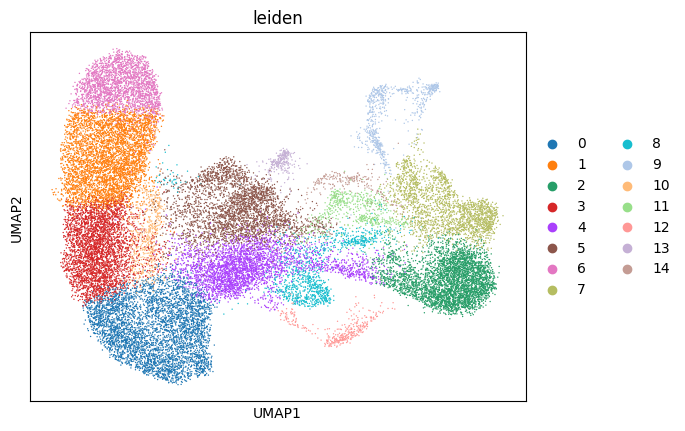

In [8]:
sc.pl.umap(sdata['table'],color='leiden')

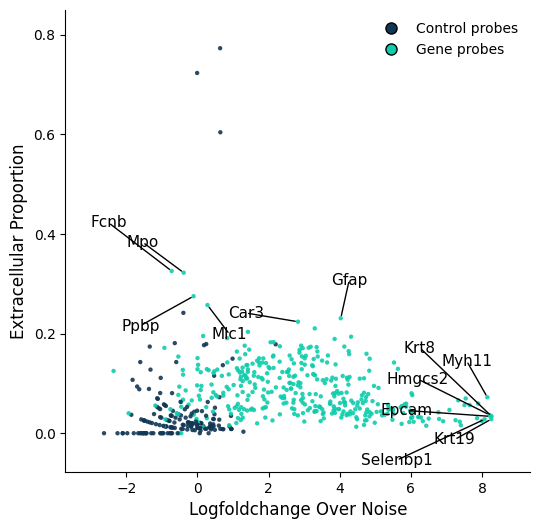

In [23]:
pl.metric_scatter(sdata,x='logfoldchange_over_noise',y='extracellular_proportion',size=10,linewidth=0,label_top_n_x=6,label_top_n_y=6,save=True,figures_path=saving_path,custom_plot_filename='scatter_extrcellular_logfoldratio.pdf')

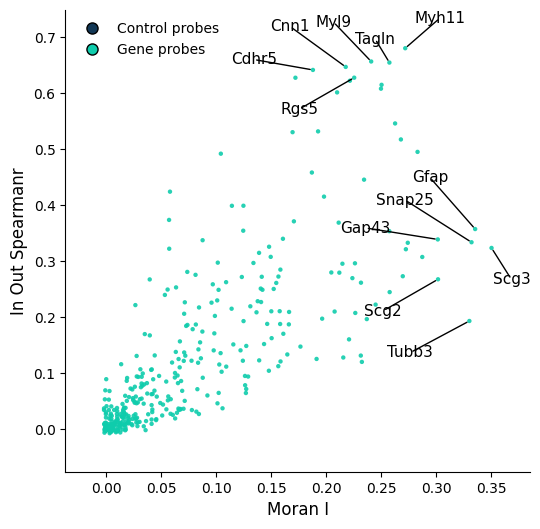

In [32]:
pl.metric_scatter(sdata,x='moran_I',y='in_out_spearmanR',size=10,linewidth=0,label_top_n_x=6,label_top_n_y=6,save=True,figures_path=saving_path,custom_plot_filename='scatter_inout_spearmanR_logfoldratio.pdf')

We plot and visualize the expression of AQP3 and OGN

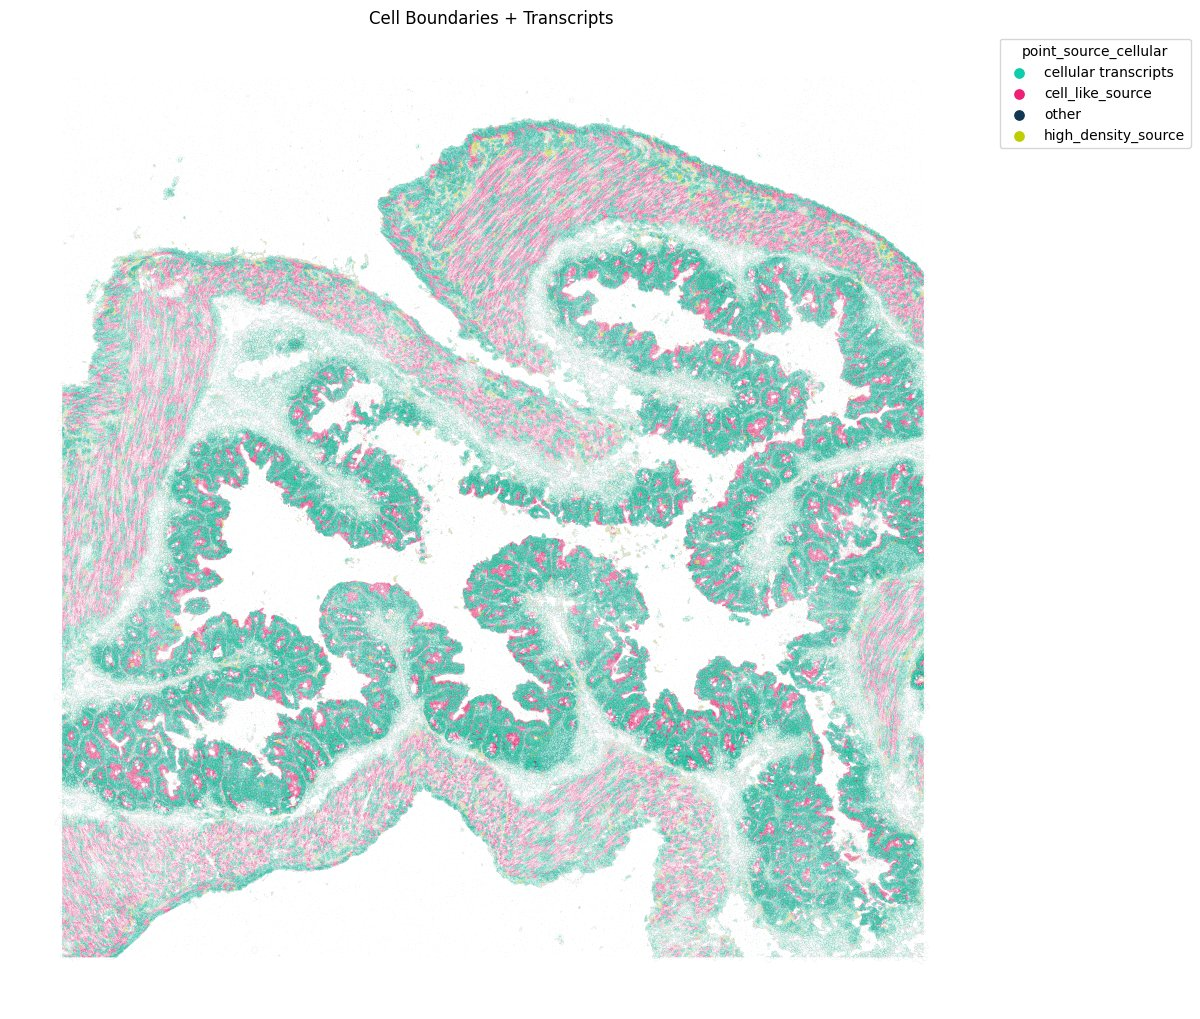

In [25]:
fig=pl.spatial_transcripts(sdata,scatter_size=0.01,boundary_linewidth=0.06,alpha=1,figsize=(12,12))
plt.savefig(os.path.join(saving_path,'mscolon_by_transcript_type.pdf'))

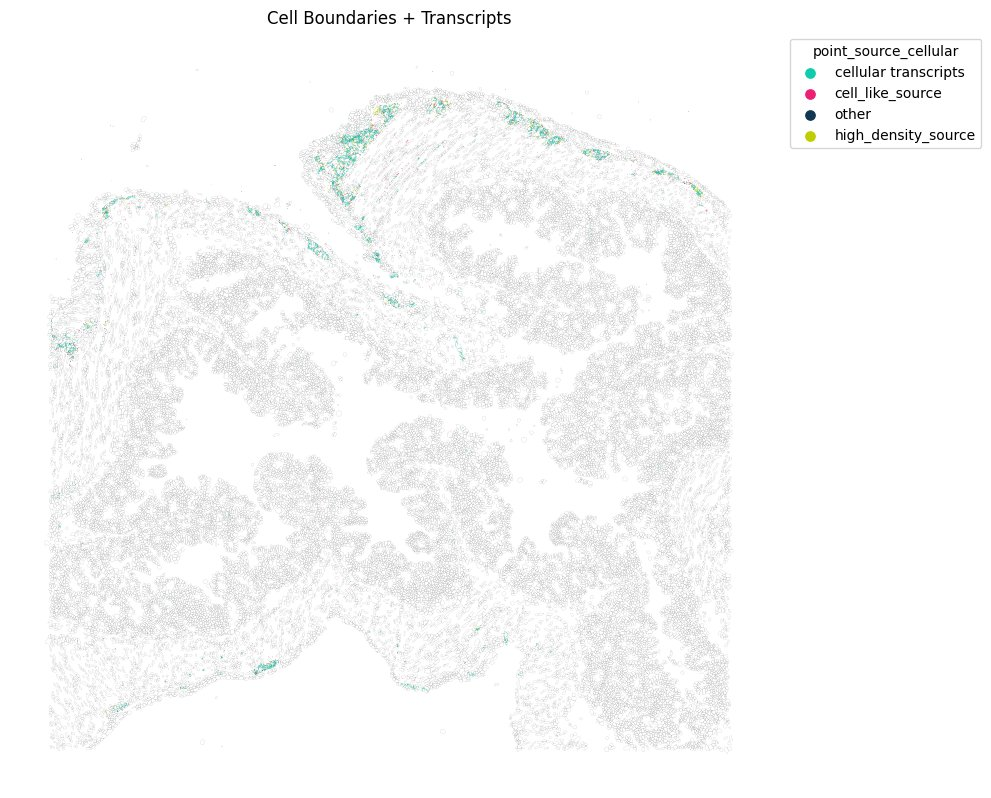

In [28]:
fig=pl.spatial_transcripts(sdata, gene_list=['Gfap'],scatter_size=0.1,figsize=(10,10),boundary_linewidth=0.1)
plt.savefig(os.path.join(saving_path,'spatial_transcript_mscolon_gfap.pdf'))

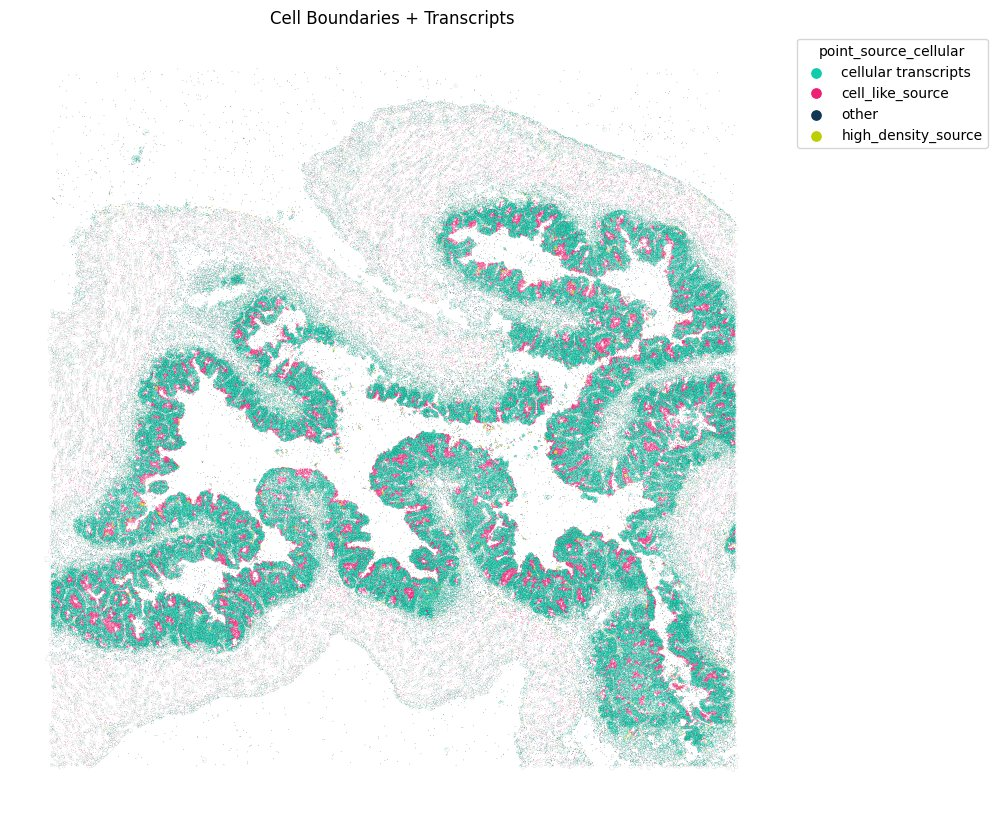

In [29]:
fig=pl.spatial_transcripts(sdata, gene_list=['Krt8'],scatter_size=0.1,figsize=(10,10),boundary_linewidth=0.1)
plt.savefig(os.path.join(saving_path,'spatial_transcript_mscolon_krt8.pdf'))

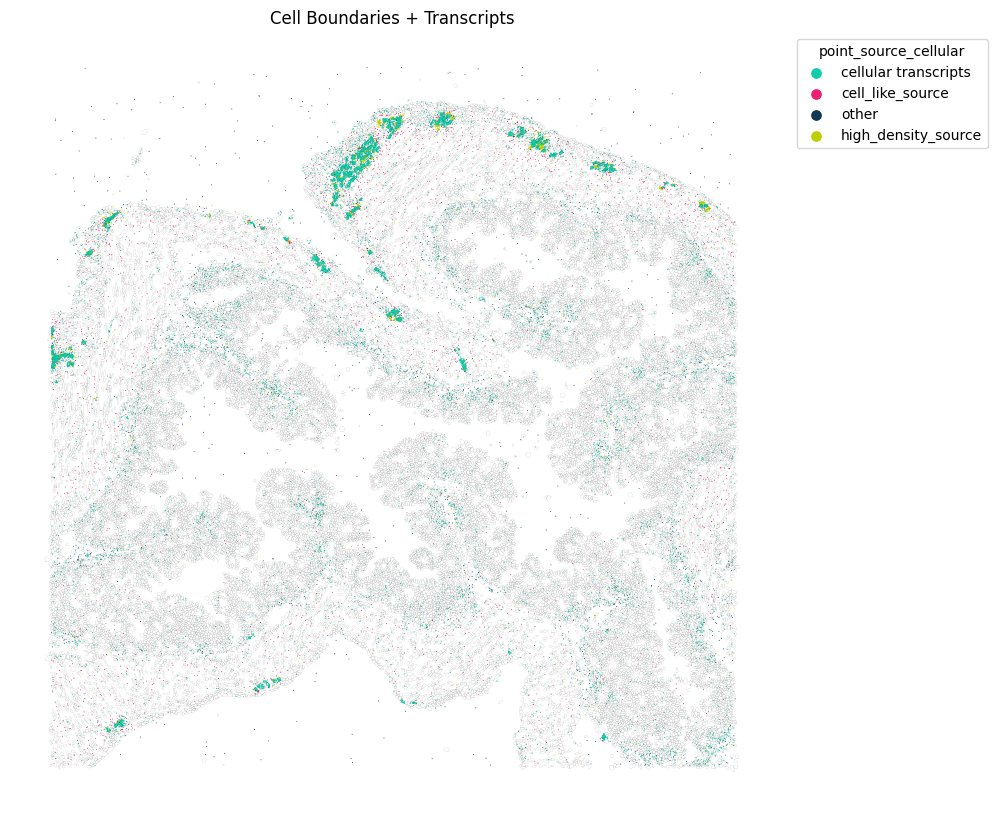

In [34]:
fig=pl.spatial_transcripts(sdata, gene_list=['Scg2'],scatter_size=0.3,figsize=(10,10),boundary_linewidth=0.1)
plt.savefig(os.path.join(saving_path,'spatial_transcript_mscolon_scg2.pdf'))

# Quantify glial genes

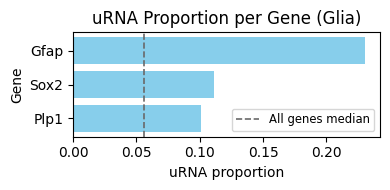

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl 

mpl.rcParams['pdf.fonttype'] = 42  
mpl.rcParams['ps.fonttype'] = 42  

glial_markers = ['Gfap', 'Plp1', 'Sox2']
urna_metadata = sdata['xrna_metadata'].var
glia_metadata = urna_metadata.loc[urna_metadata.index.isin(glial_markers), :]

# Sort the DataFrame by 'extracellular_proportion' in ascending order
sorted_df = glia_metadata.sort_values('extracellular_proportion', ascending=True)

# 1. Calculate distribution metrics for ALL genes to provide context
all_genes_median = urna_metadata['extracellular_proportion'].median()
all_genes_q25 = urna_metadata['extracellular_proportion'].quantile(0.25)
all_genes_q75 = urna_metadata['extracellular_proportion'].quantile(0.75)

# Create the plot using subplots
fig, ax = plt.subplots(figsize=(4, 2))

# 3. Add a vertical dashed line for the global median of all genes
ax.axvline(all_genes_median, color='dimgray', linestyle='--', linewidth=1.2, label='All genes median', zorder=3)

# 4. Create the horizontal bar plot for glial markers
# (zorder=3 ensures the bars stay in front of the background distribution span)
ax.barh(sorted_df.index, sorted_df['extracellular_proportion'], color='skyblue', zorder=2)

# Add labels and title
ax.set_ylabel('Gene')
ax.set_xlabel('uRNA proportion')
ax.set_title('uRNA Proportion per Gene (Glia)')

# Add a legend to define the background context features
ax.legend(loc='lower right', frameon=True, fontsize='small')

# Tight layout for better spacing
plt.tight_layout()
plt.savefig(os.path.join(saving_path, 'glial_markers_proportion_bar.pdf'))

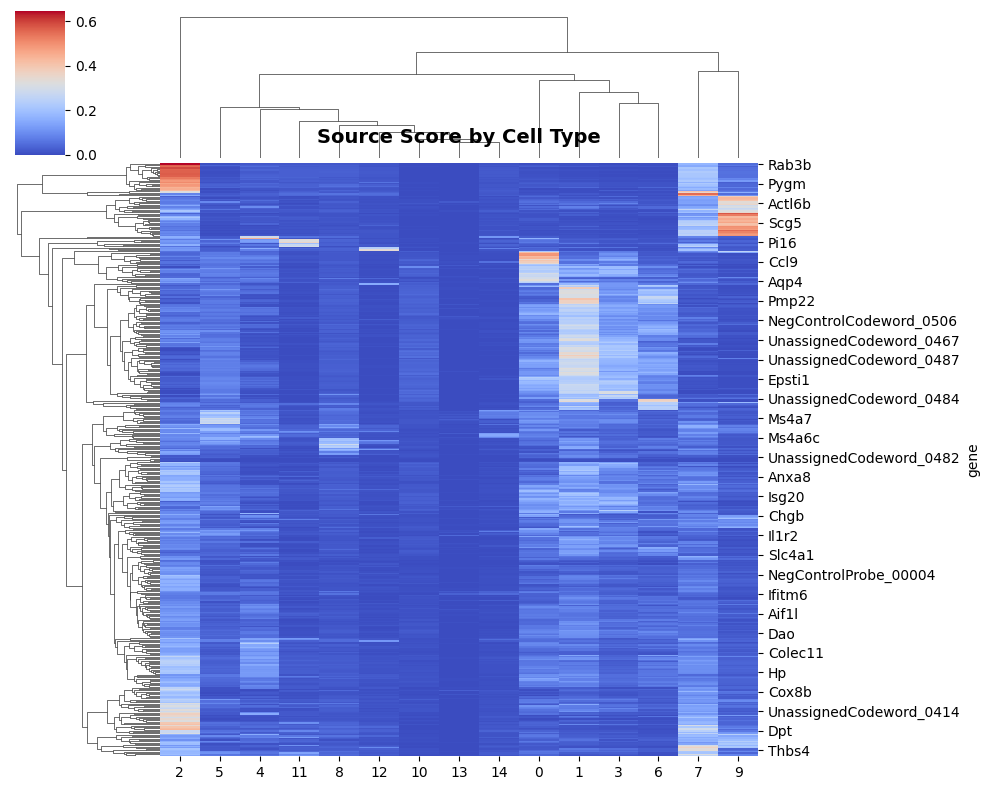

In [46]:
pl.source_score_by_celltype(sdata)

In [50]:
sdata['table'].obs

,cell_id,transcript_counts,control_probe_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,cell_area,nucleus_area,region,...,leiden,area,perimeter,solidity,major_axis_length,equivalent_diameter,circularity,protrusion_length,morphological_complexity,urna_source_score
23500,bimohifg-1,429,0,0,0,0,429,77.578440,49.762189,cell_circles,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.077657
23501,bimoimoc-1,270,0,0,0,0,270,47.775314,40.098751,cell_circles,...,3,1718.0,160.367532,0.966798,58.354287,46.769921,0.839460,5.792183,0.033202,0.329448
23502,bimomjci-1,471,0,0,0,0,471,90.899535,60.328752,cell_circles,...,3,1058.0,137.639610,0.930519,53.615899,36.702690,0.701792,8.456605,0.069481,0.324878
23503,bimopidl-1,200,0,0,0,0,200,51.523283,32.241564,cell_circles,...,0,2013.0,189.095454,0.912925,68.683800,50.626388,0.707443,9.028706,0.087075,0.887550
23504,bimpfbem-1,355,0,0,0,0,355,83.584222,46.104533,cell_circles,...,0,1141.0,145.095454,0.910615,50.191322,38.115172,0.681064,6.038075,0.089385,1.374046
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
218173,ohcekhpa-1,60,0,0,0,0,60,62.044690,62.044690,cell_circles,...,4,2939.0,218.066017,0.971249,74.548931,61.172306,0.776665,6.688313,0.028751,1.123490
218176,ohcfcepm-1,34,1,0,0,0,35,36.666876,6.096094,cell_circles,...,4,644.0,96.669048,0.956909,33.080179,28.635053,0.866006,2.222563,0.043091,1.128811
218178,ohcfmmdk-1,222,0,0,0,0,222,112.710004,16.978751,cell_circles,...,2,326.0,91.254834,0.857895,36.104282,20.373416,0.491944,7.865433,0.142105,19.122220
218179,ohcgajlp-1,82,0,0,0,0,82,28.087189,28.087189,cell_circles,...,2,2496.0,192.166522,0.972341,60.238477,56.373805,0.849374,1.932336,0.027659,7.661049


<Axes: ylabel='urna_source_score'>

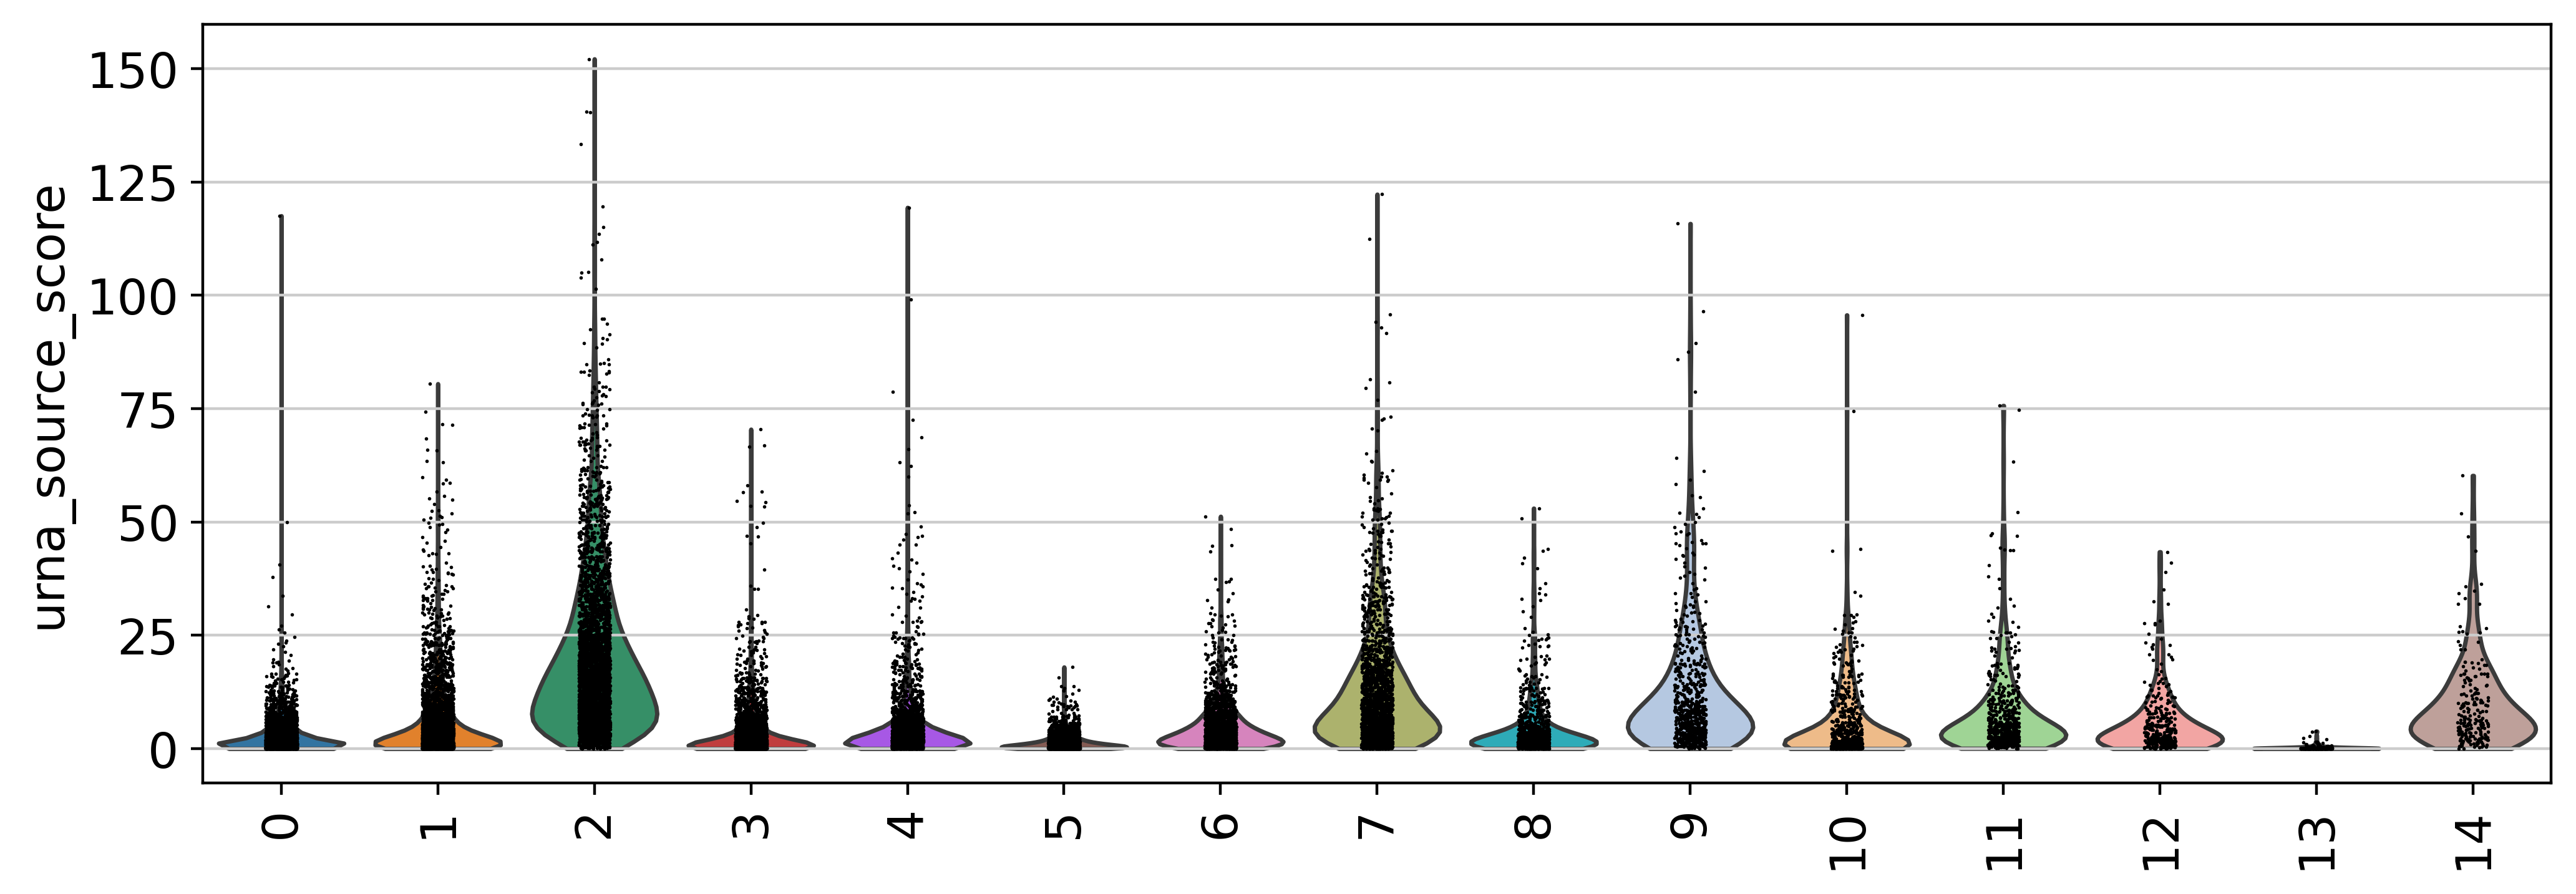

In [51]:
import matplotlib
import matplotlib.pyplot as plt
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=(10,4), color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')


# Your violin plot
sc.pl.violin(
    sdata['table'],
    'urna_source_score',
    groupby='leiden',
    rotation=90,
    show=False)


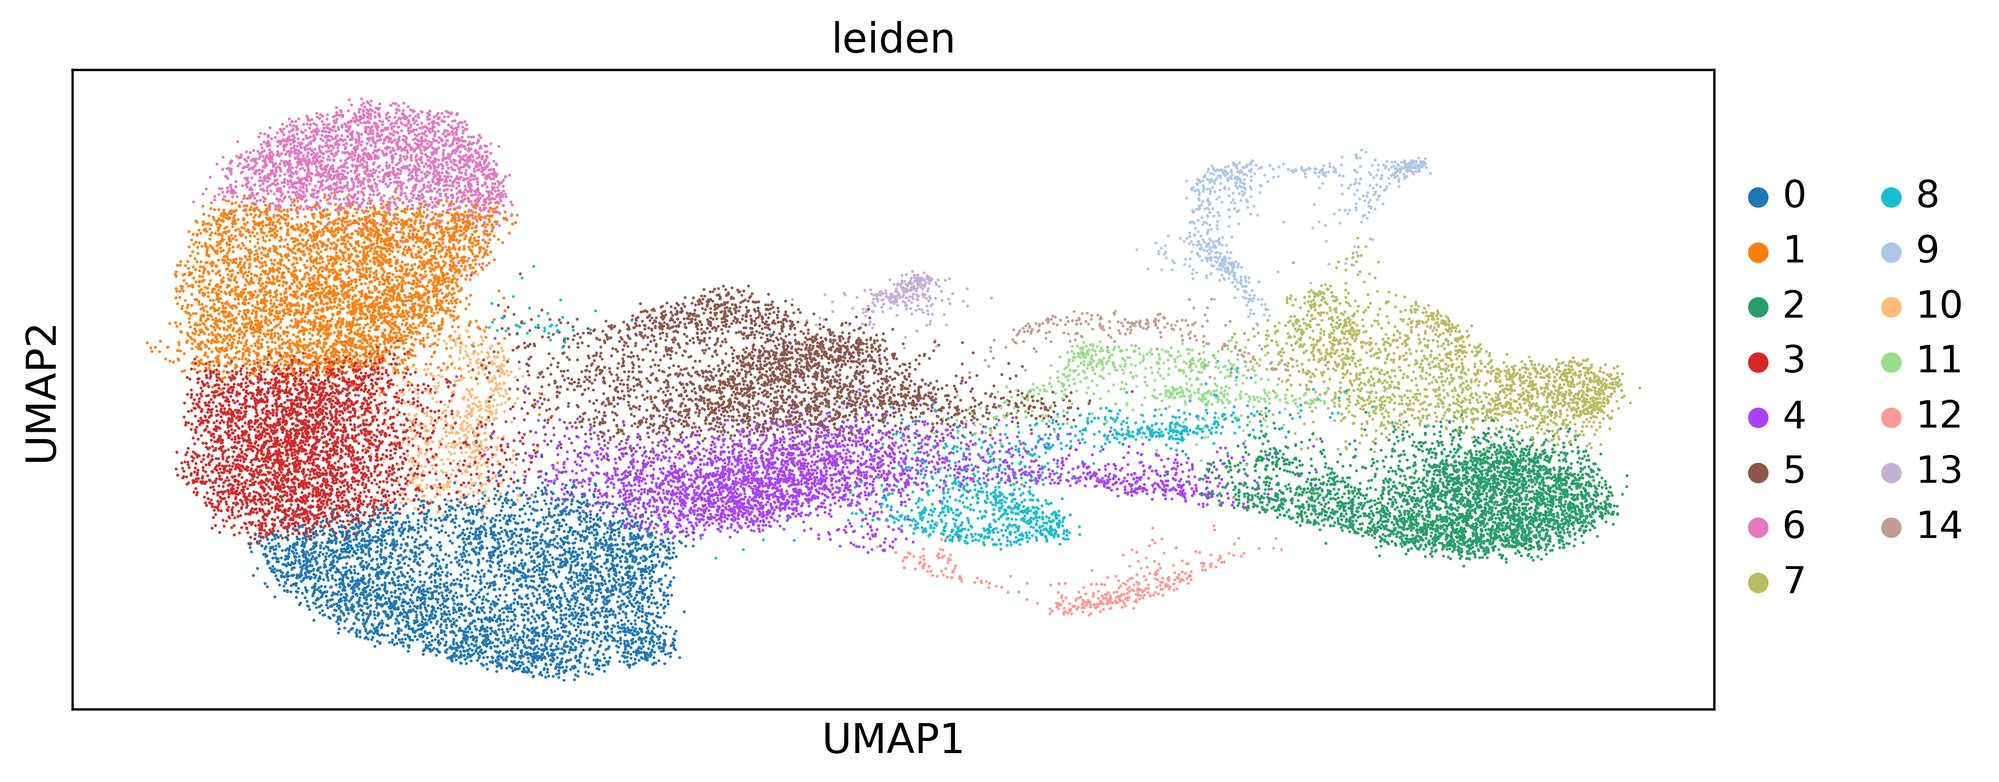

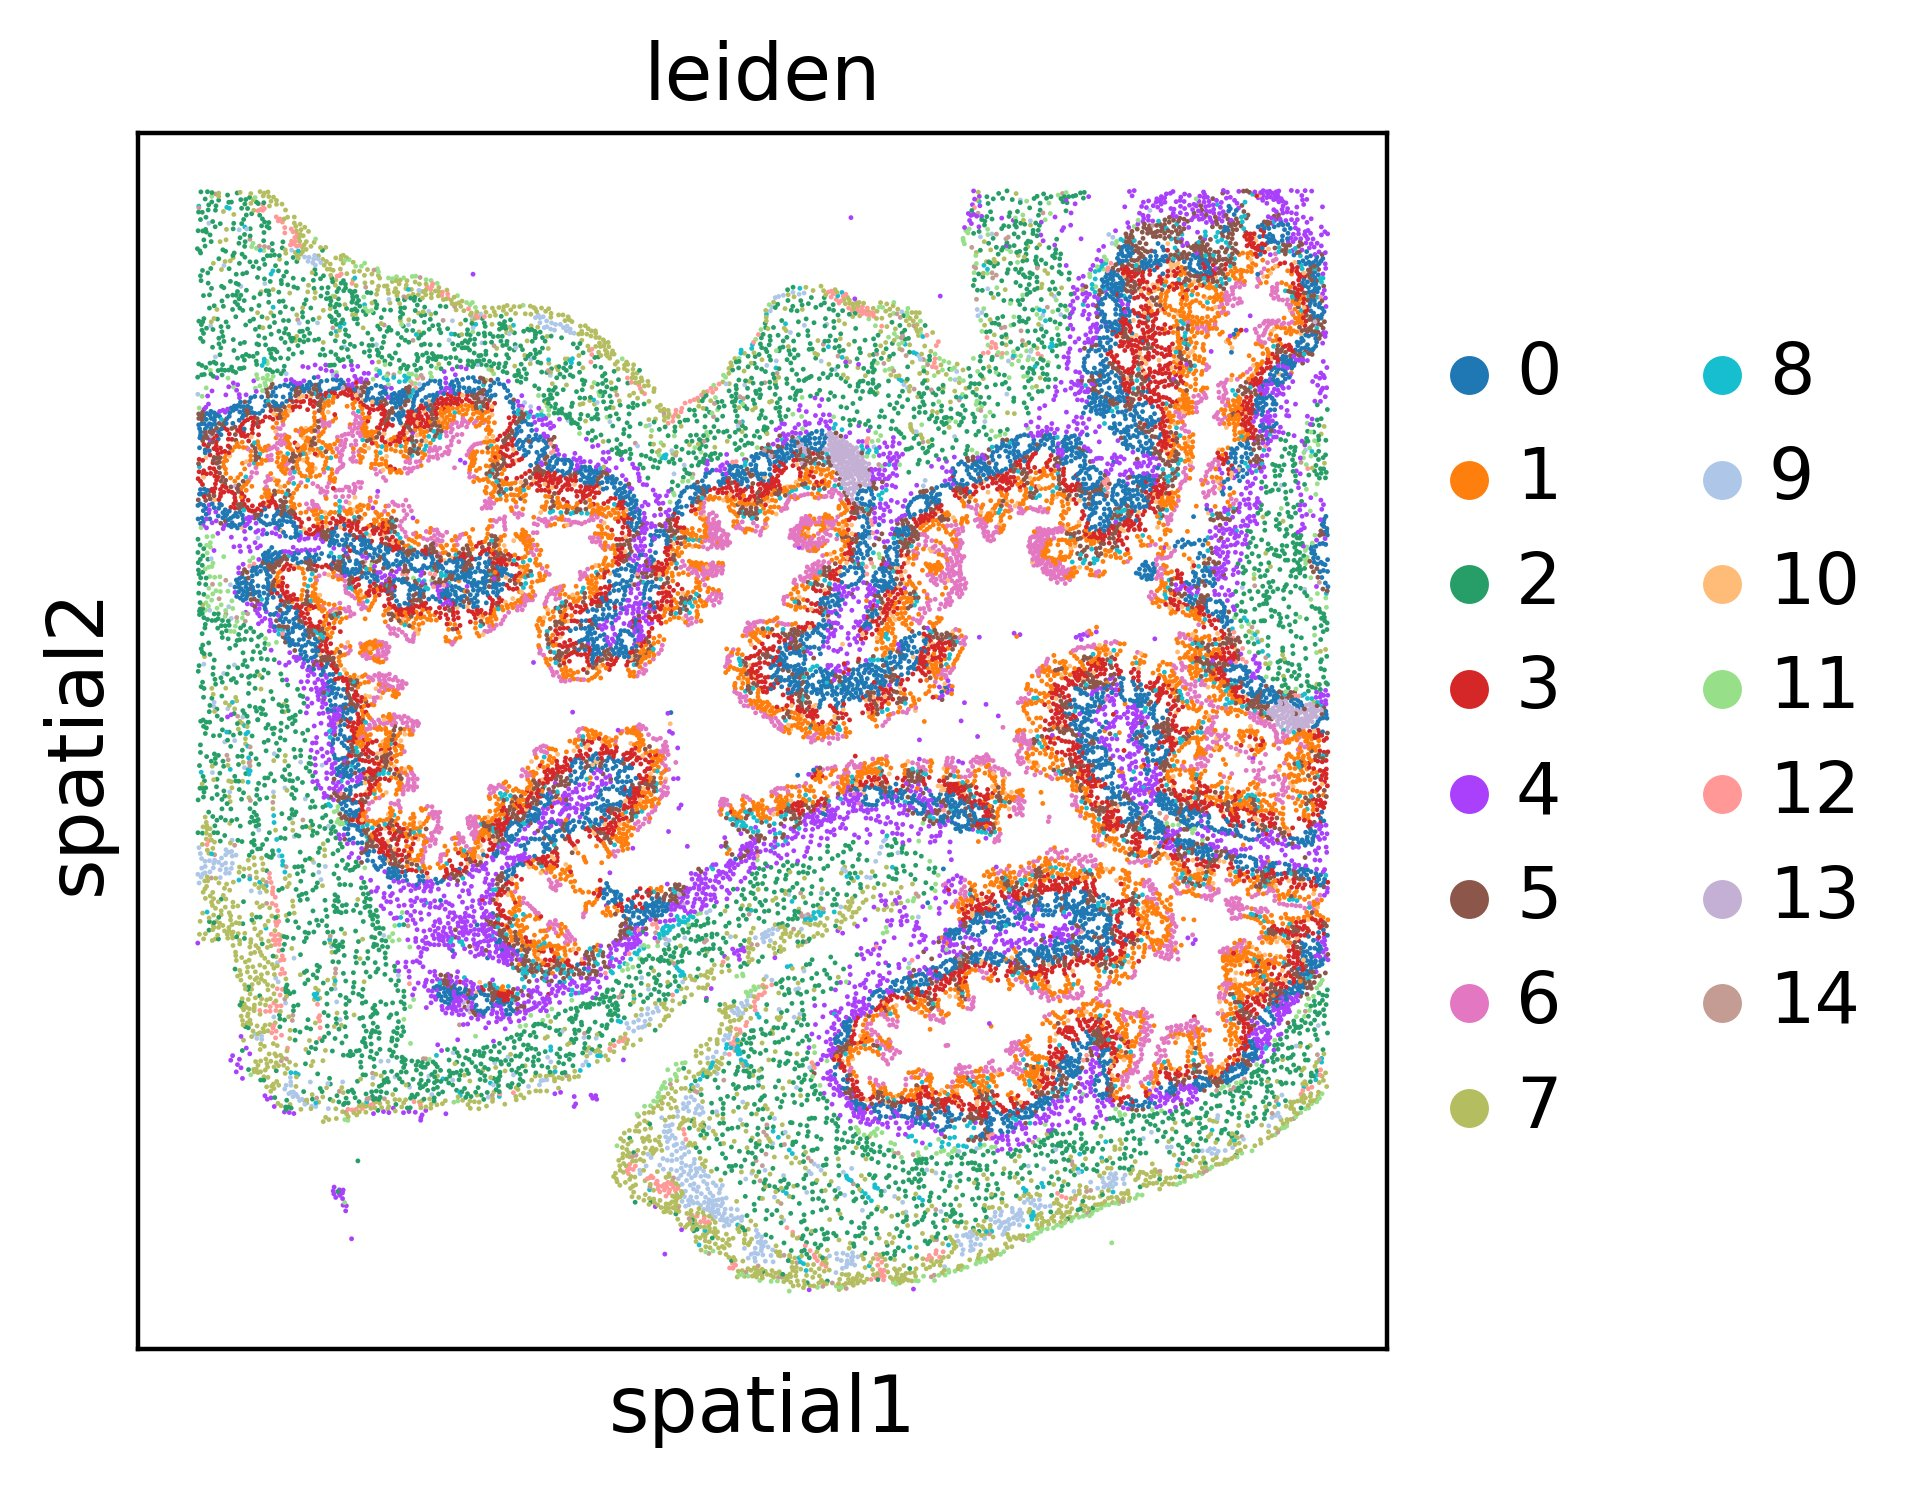

In [53]:
sc.pl.umap(sdata['table'],color='leiden')
sc.pl.spatial(sdata['table'],color='leiden',spot_size=10)

# Source score expression

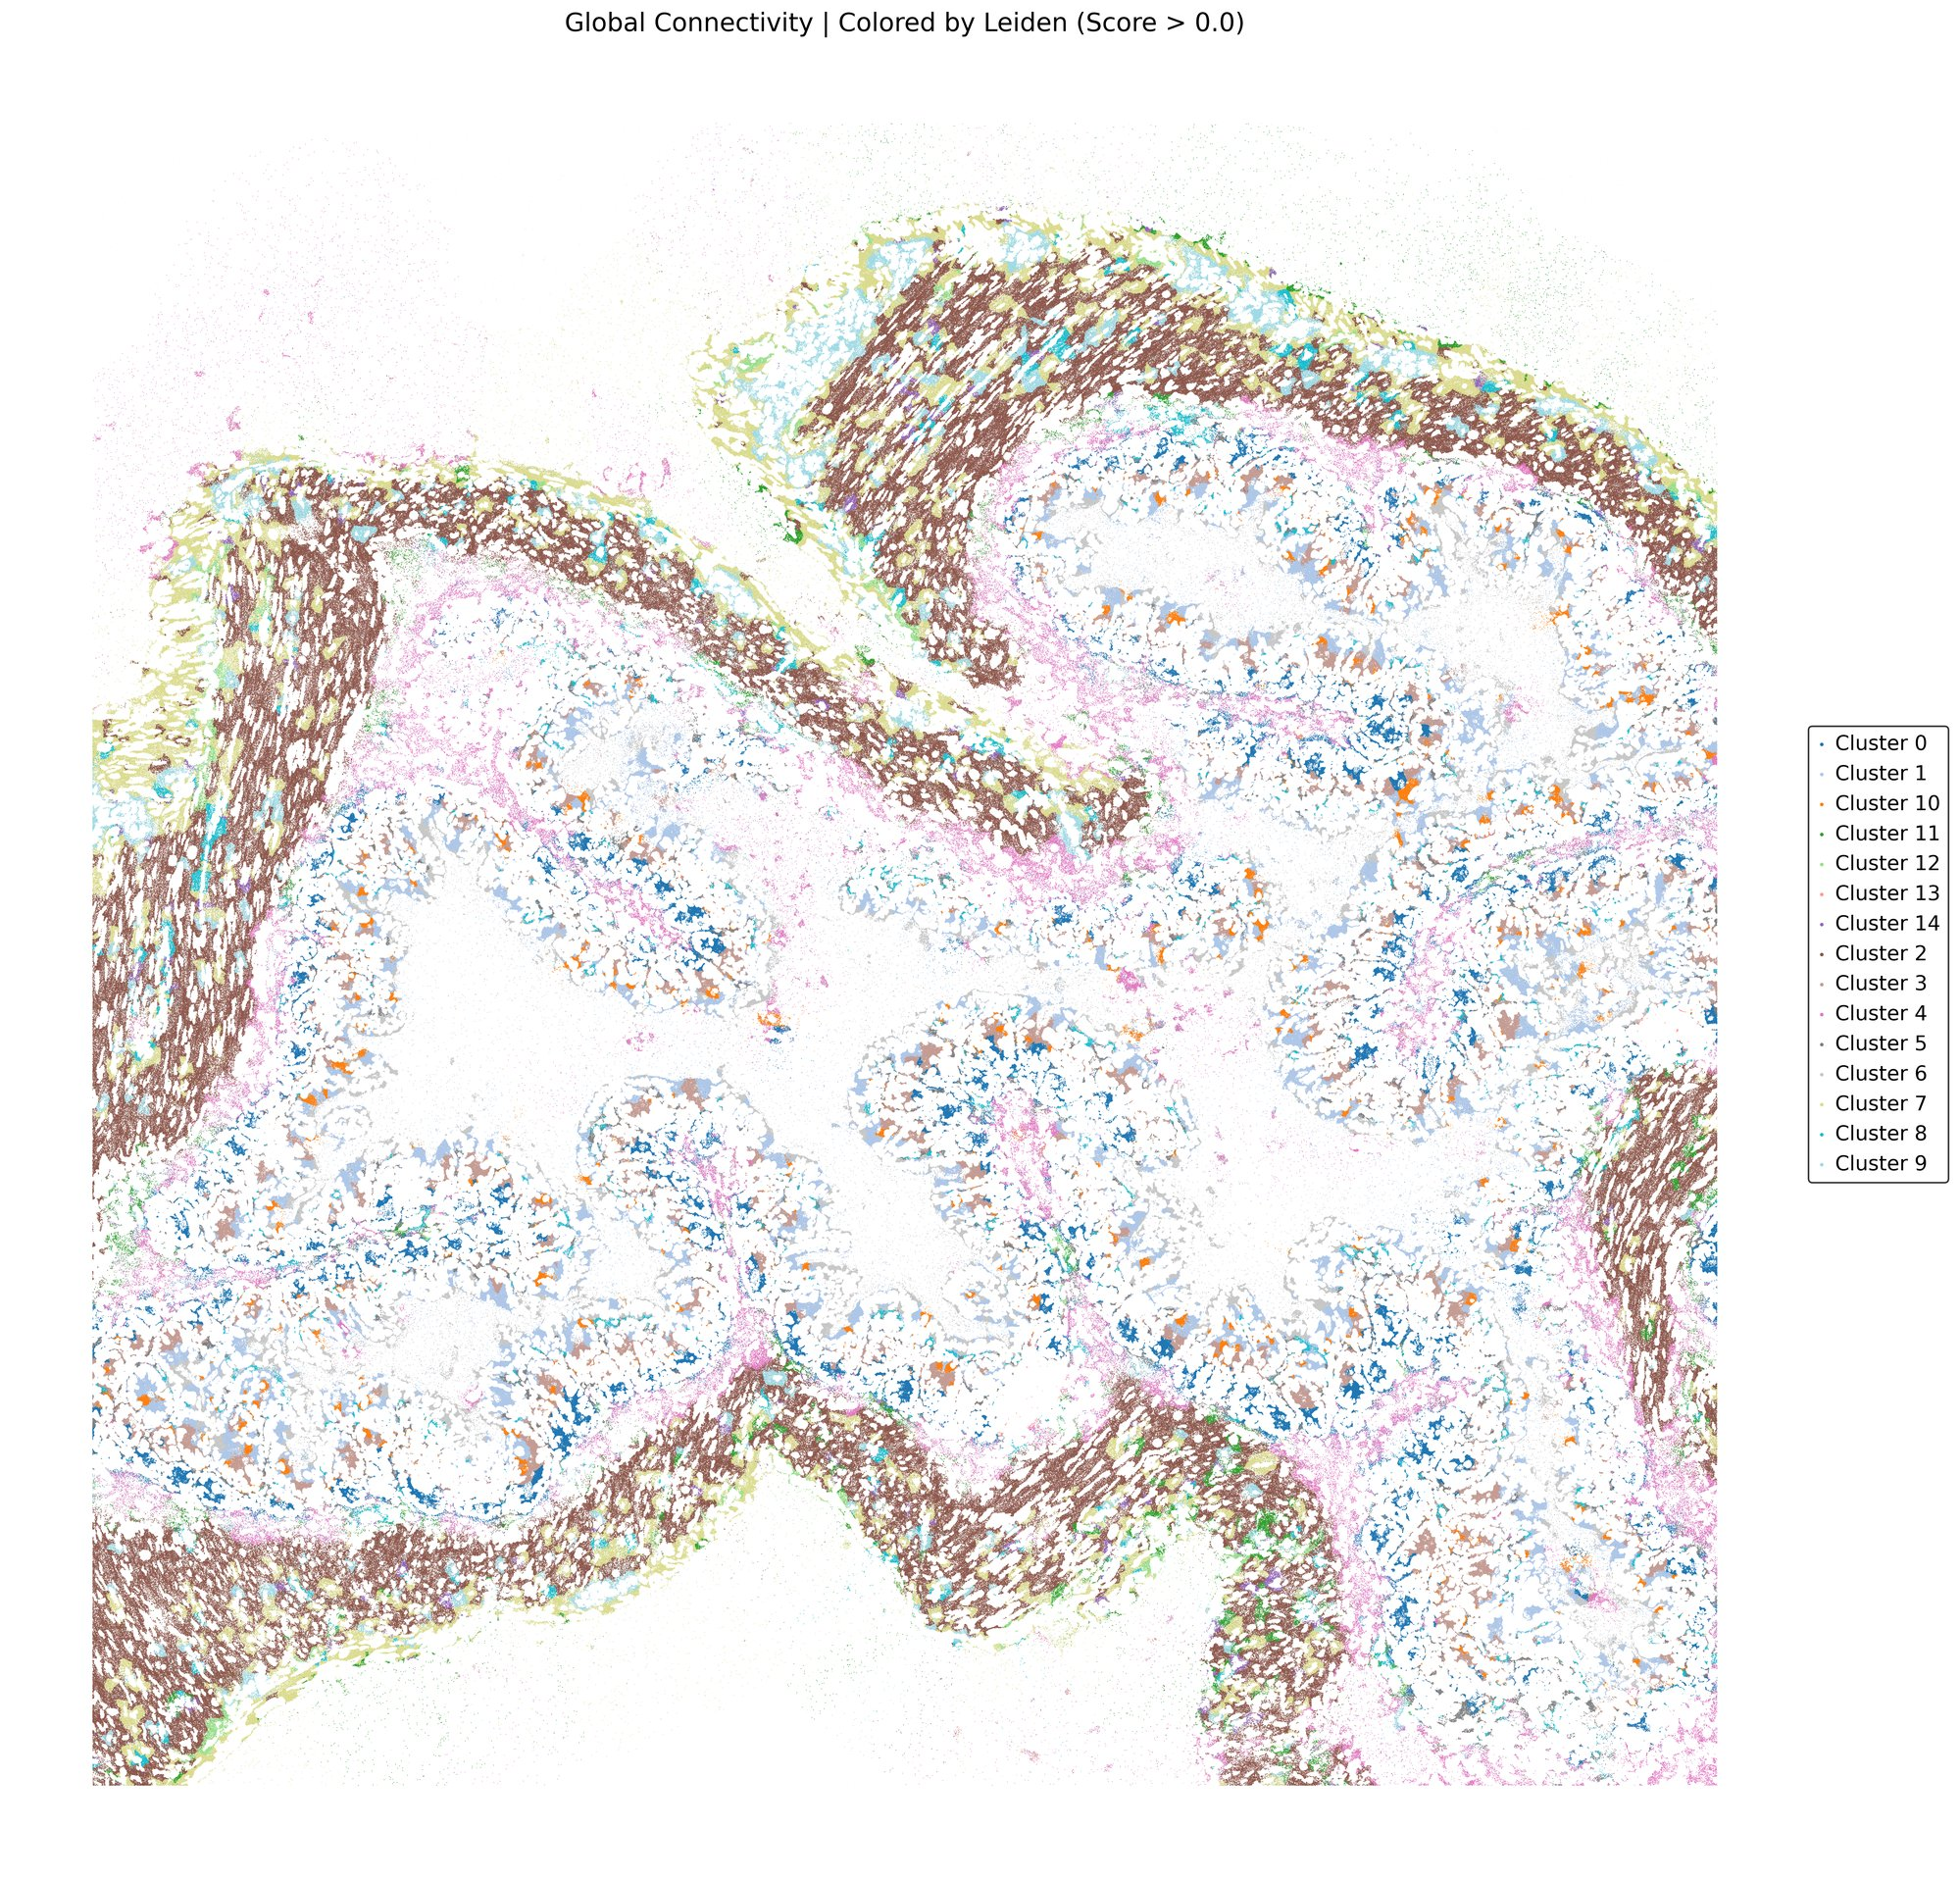

In [74]:
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import ListedColormap
import pandas as pd
import numpy as np
import geopandas as gpd
from shapely.geometry import box
from shapely.affinity import affine_transform

def spatial_transcripts_source(
    sdata, 
    cell_color_key: str = "leiden",       # Column in sdata['table'].obs for intracellular
    extra_color_key: str = "leiden",      # Column in sdata['table'].obs (mapped via parent) OR in sdata.tables["source_score"].obs
    gene_list: str | list[str] | None = None, # Specific gene(s) to isolate
    gene_key: str = "gene",       # Column name in transcript points representing gene identity
    separate_compartments: bool = False,  # If True, splits the legend/colors into "Cell: X" and "Extra: X"
    use_roi: bool = False,
    roi: tuple[float, float, float, float] | None = None, # (xmin, xmax, ymin, ymax)
    padding: float = 0,           
    point_size: float = 0.1, 
    min_score: float = 0.1,       
    show_edges: bool = False,
    edge_alpha: float = 0.1,
    fig_bg_color: str = 'white', 
    ambient_color: str = 'grey', 
    palette: str = 'tab20',
    shapes_key: str = "cell_boundaries",
    boundary_linewidth: float = 0.5,
    boundary_zorder: int = 4
):
    # 1. Data Access
    res_obs = sdata.tables["source_score"].obs
    cells = sdata['table']
    all_transcripts = sdata.points["transcripts"].compute()
    
    all_transcripts.index = all_transcripts.index.astype(int)
    res_obs.index = res_obs.index.astype(int)
    
    # --- CRITICAL FILTER: Keep ONLY the selected genes if requested ---
    if gene_list is not None:
        if isinstance(gene_list, str):
            gene_list = [gene_list]
        all_transcripts = all_transcripts[all_transcripts[gene_key].isin(gene_list)].copy()
        
        # If no transcripts left after filtering, exit early gracefully
        if all_transcripts.empty:
            print(f"No transcripts found for gene(s): {gene_list}")
            return None, None

    # 2. Extract Global Identity Mappings
    cell_map = dict(zip(
        cells.obs['cell_id'].astype(str).str.strip(), 
        cells.obs[cell_color_key].astype(str)
    ))
    
    if extra_color_key in res_obs.columns:
        extra_map = dict(zip(
            res_obs.index.astype(str).str.strip(),
            res_obs[extra_color_key].astype(str)
        ))
        direct_extra_mapping = True
    elif extra_color_key in cells.obs.columns:
        parent_to_extra_trait_map = dict(zip(
            cells.obs['cell_id'].astype(str).str.strip(),
            cells.obs[extra_color_key].astype(str)
        ))
        direct_extra_mapping = False
    else:
        raise KeyError(f"'{extra_color_key}' not found in source_score or table metadata.")
    
    centroid_map = dict(zip(
        cells.obs['cell_id'].astype(str).str.strip(), 
        cells.obsm['spatial']
    ))

    # 3. Handle ROI Bounds
    if use_roi and roi is not None:
        x_min, x_max, y_min, y_max = roi
        df_roi = all_transcripts[
            (all_transcripts.x.between(x_min, x_max)) & 
            (all_transcripts.y.between(y_min, y_max))
        ].copy()
    elif padding > 0:
        x_min = all_transcripts['x'].min() + padding
        x_max = all_transcripts['x'].max() - padding
        y_min = all_transcripts['y'].min() + padding
        y_max = all_transcripts['y'].max() - padding
        df_roi = all_transcripts[
            (all_transcripts.x.between(x_min, x_max)) & 
            (all_transcripts.y.between(y_min, y_max))
        ].copy()
    else:
        x_min, x_max = all_transcripts['x'].min(), all_transcripts['x'].max()
        y_min, y_max = all_transcripts['y'].min(), all_transcripts['y'].max()
        df_roi = all_transcripts.copy()

    # 4. Assignment Logic & Subsetting
    df_roi = df_roi.join(res_obs[['predicted_parent', 'assignment_score']], how='left')
    
    df_roi['parent_id'] = df_roi['predicted_parent'].astype(str).str.strip()
    df_roi['clean_cell_id'] = df_roi['cell_id'].astype(str).str.strip()
    df_roi['transcript_id_str'] = df_roi.index.astype(str).str.strip()
    
    if direct_extra_mapping:
        is_halo = (df_roi['assignment_score'] >= min_score) & (df_roi['transcript_id_str'].isin(extra_map))
    else:
        is_halo = (df_roi['assignment_score'] >= min_score) & (df_roi['parent_id'].isin(parent_to_extra_trait_map))
        
    is_body = (df_roi['overlaps_cell'].astype(str).str.lower() == 'true') & (df_roi['clean_cell_id'].isin(cell_map))

    df_roi['cell_label'] = np.nan
    df_roi['extra_label'] = np.nan

    df_roi.loc[is_body, 'cell_label'] = df_roi.loc[is_body, 'clean_cell_id'].map(cell_map)
    if direct_extra_mapping:
        df_roi.loc[is_halo, 'extra_label'] = df_roi.loc[is_halo, 'transcript_id_str'].map(extra_map)
    else:
        df_roi.loc[is_halo, 'extra_label'] = df_roi.loc[is_halo, 'parent_id'].map(parent_to_extra_trait_map)

    # Unified label designation field if not forced to separate them
    if not separate_compartments:
        df_roi['unified_label'] = df_roi['cell_label'].fillna(df_roi['extra_label'])

    # 5. Harmonized Color Generation Logic
    def extract_uns_colors(uns_dict, key):
        for possible_key in [f"{key}_colors", "colors"]:
            if possible_key in uns_dict:
                return list(uns_dict[possible_key])
        return None

    if not separate_compartments:
        # UNIFIED SCATTER MODE (Shared categories, single entries per cluster in legend)
        unique_labels = sorted(list(df_roi['unified_label'].dropna().unique()))
        uns_colors = None
        if 'uns' in dir(cells) or hasattr(cells, 'uns'):
            if cell_color_key in cells.uns:
                uns_colors = extract_uns_colors(cells.uns, cell_color_key)
        
        if uns_colors and len(uns_colors) >= len(unique_labels):
            cat_order = list(cells.obs[cell_color_key].astype("category").cat.categories)
            unified_colors = {lbl: uns_colors[cat_order.index(lbl)] for lbl in unique_labels if lbl in cat_order}
        else:
            cmap = plt.get_cmap(palette)
            unified_colors = {l: cmap(i / max(1, len(unique_labels)-1)) for i, l in enumerate(unique_labels)}
    else:
        # SEPARATED MODE (Unique groups for cell vs extracellular)
        unique_cells = set(df_roi['cell_label'].dropna().unique())
        unique_extra = set(df_roi['extra_label'].dropna().unique())
        matching_elements = (unique_cells == unique_extra) and (cell_color_key == extra_color_key)
        
        if matching_elements:
            uns_colors = None
            if 'uns' in dir(cells) or hasattr(cells, 'uns'):
                if cell_color_key in cells.uns:
                    uns_colors = extract_uns_colors(cells.uns, cell_color_key)
            
            all_labels = sorted(list(unique_cells.union(unique_extra)))
            if uns_colors and len(uns_colors) >= len(all_labels):
                cat_order = list(cells.obs[cell_color_key].astype("category").cat.categories)
                colors = {lbl: uns_colors[cat_order.index(lbl)] for lbl in all_labels if lbl in cat_order}
            else:
                cmap = plt.get_cmap(palette)
                colors = {l: cmap(i / max(1, len(all_labels)-1)) for i, l in enumerate(all_labels)}
            cell_colors = extra_colors = colors
        else:
            sorted_cells = sorted(list(unique_cells))
            cmap_cells = plt.get_cmap(palette)
            cell_colors = {l: cmap_cells(i / max(1, len(sorted_cells)-1)) for i, l in enumerate(sorted_cells)}
            
            sorted_extra = sorted(list(unique_extra))
            cmap_extra = plt.get_cmap("Set3" if palette != "Set3" else "tab20b")
            extra_colors = {l: cmap_extra(i / max(1, len(sorted_extra)-1)) for i, l in enumerate(sorted_extra)}

    # 6. Geometric Borders Processing
    cb = sdata[shapes_key]
    df_shapes = cb.copy()
    try:
        from spatialdata import get_transformation
        trans = get_transformation(cb)
        if hasattr(trans, "matrix") and trans.matrix is not None:
            m = trans.matrix 
            params = [m[0,0], m[0,1], m[1,0], m[1,1], m[0,2], m[1,2]]
            df_shapes["geometry"] = df_shapes["geometry"].apply(lambda g: affine_transform(g, params))
    except: 
        pass
        
    gdf = gpd.GeoDataFrame(df_shapes, geometry="geometry")
    if (use_roi and roi is not None) or padding > 0:
        roi_poly = box(x_min, y_min, x_max, y_max)
        gdf = gdf[gdf.geometry.intersects(roi_poly)]

    # 7. Rendering Setup
    text_color = 'white' if fig_bg_color in ['black', '#000000', '#252525'] else 'black'
    fig, ax = plt.subplots(figsize=(25, 25), facecolor=fig_bg_color)
    ax.set_facecolor(fig_bg_color)

    # --- Ambient Scatter Plane ---
    ambient_mask = ~(is_halo | is_body)
    ax.scatter(
        df_roi.loc[ambient_mask, 'x'], df_roi.loc[ambient_mask, 'y'], 
        c=ambient_color, s=point_size, alpha=0.1, edgecolors='none', zorder=0
    )
    
    # --- Network Connection Edges ---
    if show_edges:
        halo_data = df_roi[is_halo]
        lines = [[(row['x'], row['y']), centroid_map.get(row['parent_id'])] 
                 for _, row in halo_data.iterrows() if row['parent_id'] in centroid_map]
        lc = LineCollection(lines, colors=text_color, linewidths=0.2, alpha=edge_alpha, zorder=1)
        ax.add_collection(lc)

    # --- Structural Expressive Layer Plottings ---
    if not separate_compartments:
        # Unified plotting loop
        for lbl in unique_labels:
            subset = df_roi[df_roi['unified_label'] == lbl]
            ax.scatter(
                subset.x, subset.y, color=unified_colors[lbl], s=point_size * 2,
                label=f"Cluster {lbl}", edgecolors='none', zorder=2
            )
    else:
        # Split compartments plotting loops
        for lbl in sorted(list(unique_cells)):
            subset = df_roi[df_roi['cell_label'] == lbl]
            ax.scatter(
                subset.x, subset.y, color=cell_colors[lbl], s=point_size * 2,
                label=f"Cell: {lbl}", edgecolors='none', zorder=2
            )
        for lbl in sorted(list(unique_extra)):
            subset = df_roi[df_roi['extra_label'] == lbl]
            lbl_legend = f"Extra: {lbl}" if not matching_elements else f"Extra Halo: {lbl}"
            ax.scatter(
                subset.x, subset.y, color=extra_colors[lbl], s=point_size * 2,
                label=lbl_legend, edgecolors='none', zorder=3
            )

    # --- Structural Vector Borders ---
    border_color = 'black' if fig_bg_color == 'white' else 'white'
    gdf.plot(
        ax=ax, facecolor="none", edgecolor=border_color, 
        linewidth=boundary_linewidth, alpha=0.4, zorder=boundary_zorder
    )

    title_suffix = f" | Subsetting for {', '.join(gene_list)}" if gene_list is not None else ""
    plt.title(f"Global Connectivity | Boundaries + Expression Channels{title_suffix}", color=text_color, fontsize=16)
    
    box_pos = ax.get_position()
    ax.set_position([box_pos.x0, box_pos.y0, box_pos.width * 0.75, box_pos.height])
    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), facecolor=fig_bg_color, edgecolor=text_color, labelcolor=text_color, markerscale=5, ncol=2)

    ax.set_aspect('equal')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    plt.axis('off')
    
    return fig, ax

In [ ]:
spatial_transcripts_source(sdata, min_score=0.01, point_size=0.1)
#plt.savefig('/home/icb/sergio.salas/notebooks/troutpy_reproducibility/uRNA_source_all.png', dpi=600, bbox_inches='tight', facecolor='white')
#plt.show()

KeyboardInterrupt: 

(<Figure size 5000x5000 with 1 Axes>,
 <Axes: title={'center': 'Global Connectivity | Boundaries + Expression Channels | Subsetting for Gfap'}>)

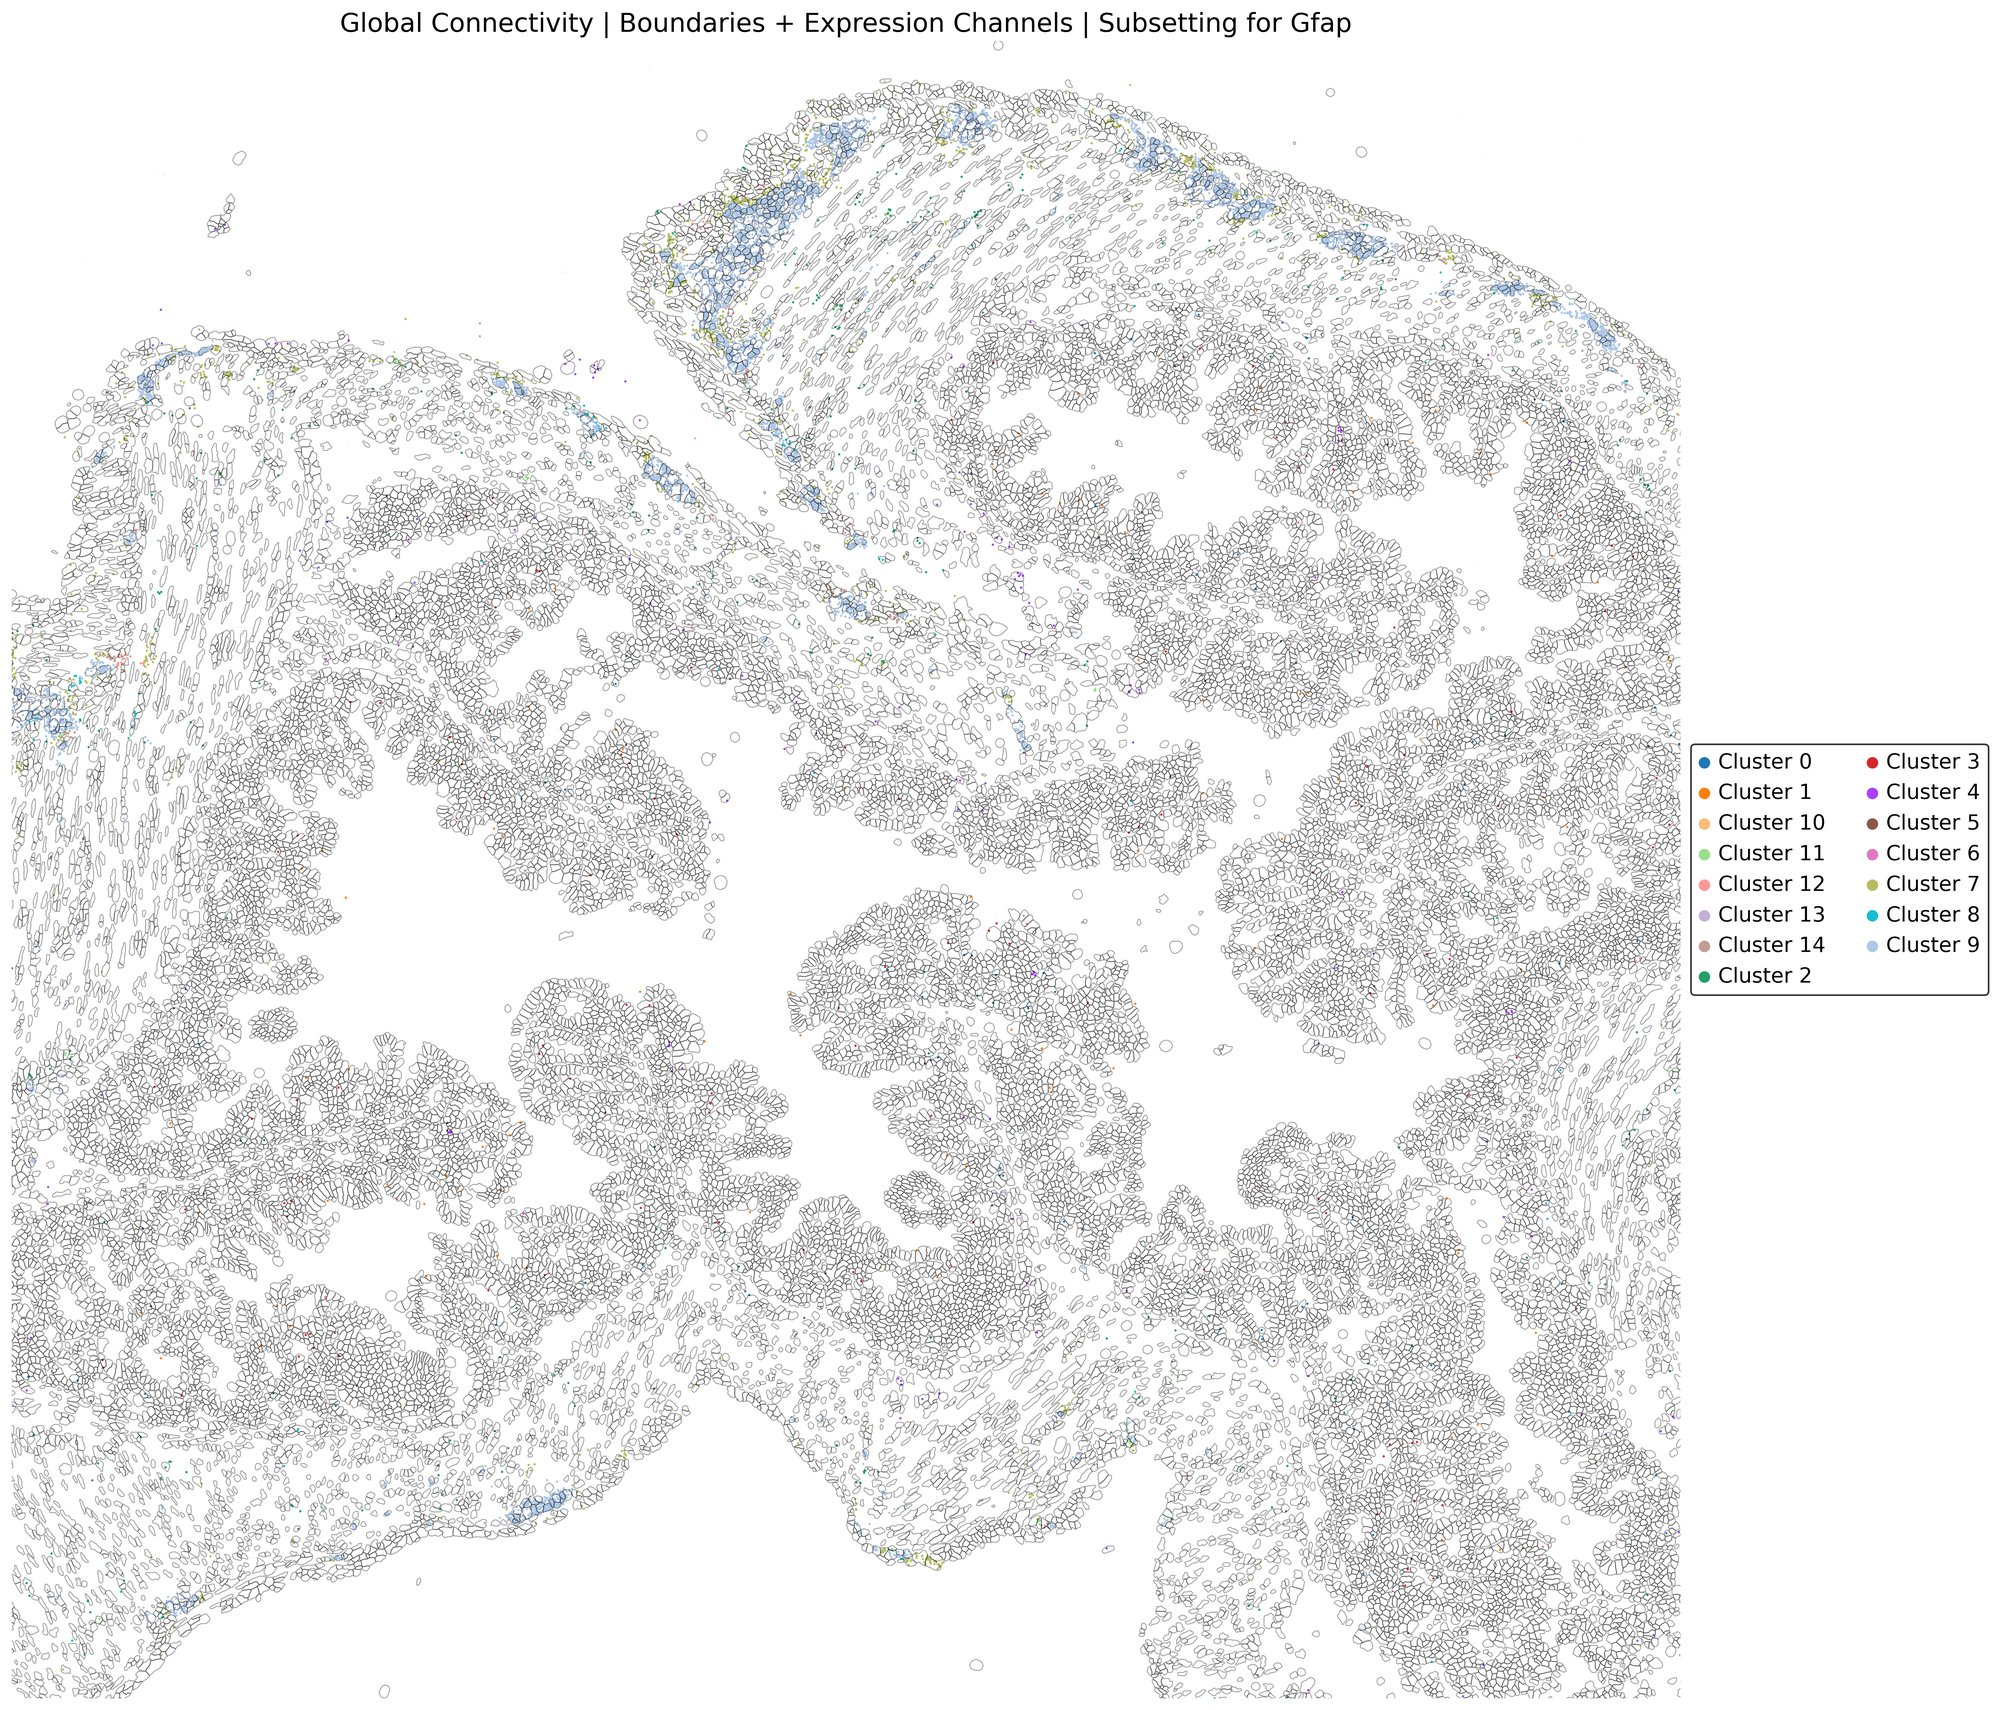

In [73]:
plot_global_connectivity_flexible(sdata,gene_list=["Gfap"], min_score=0.01, point_size=1,gene_key='gene')
#plt.savefig('/home/icb/sergio.salas/notebooks/troutpy_reproducibility/uRNA_source_all.png', dpi=600, bbox_inches='tight', facecolor='white')
#plt.show()

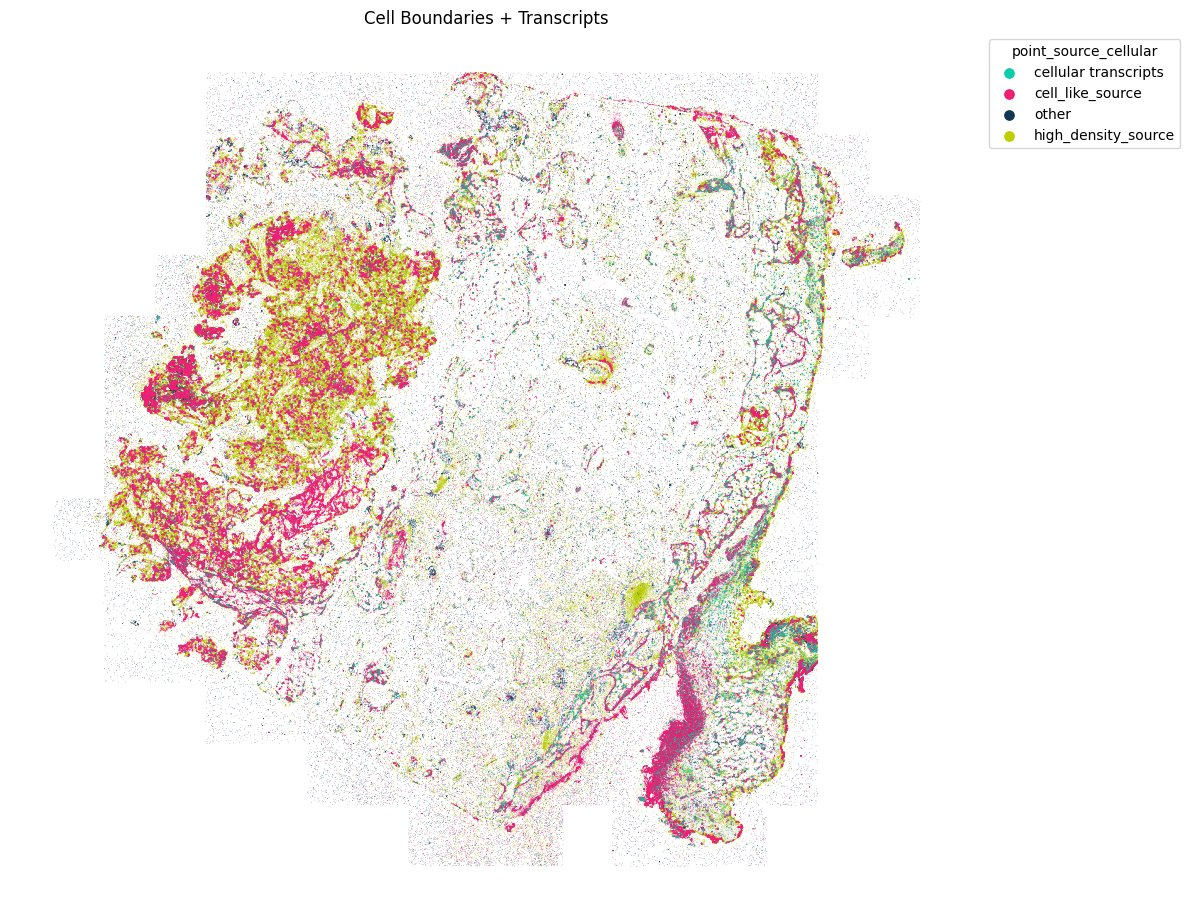

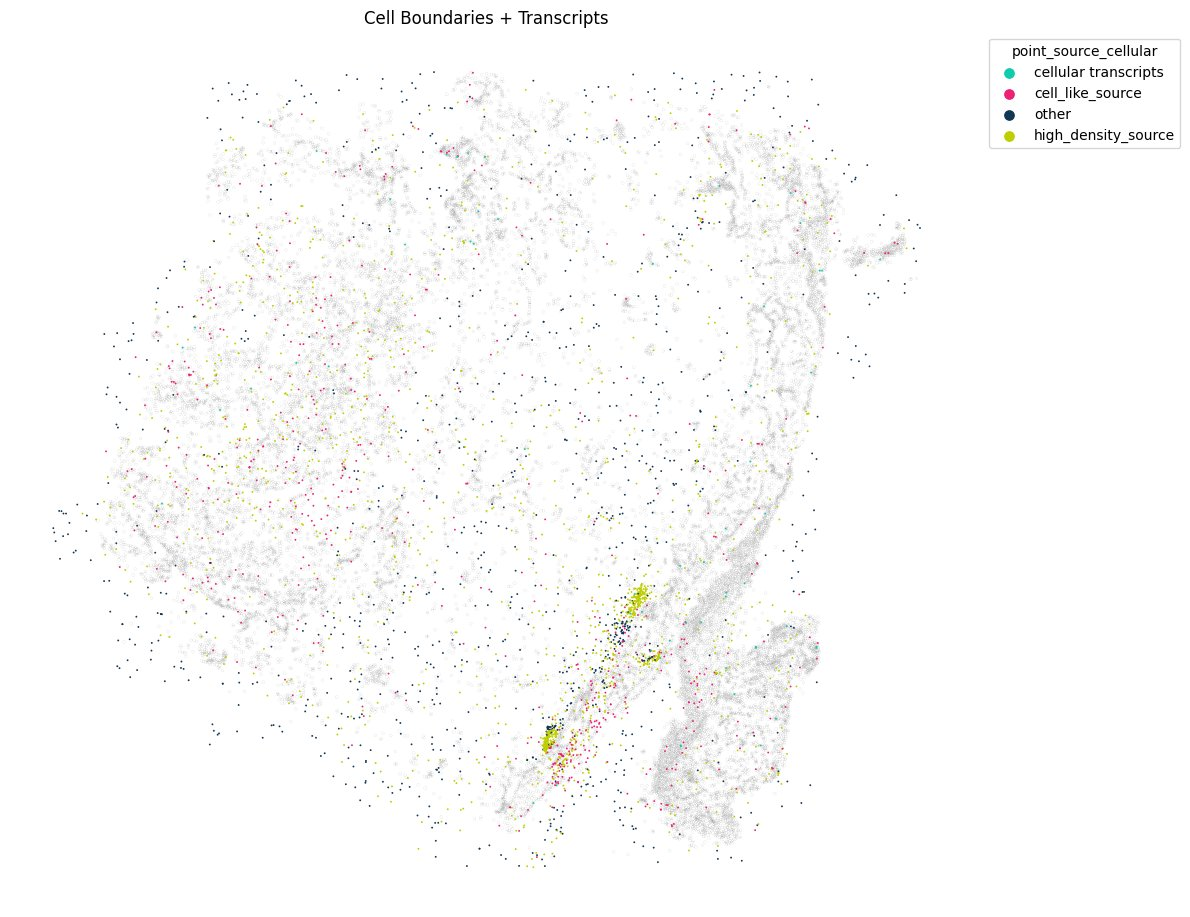

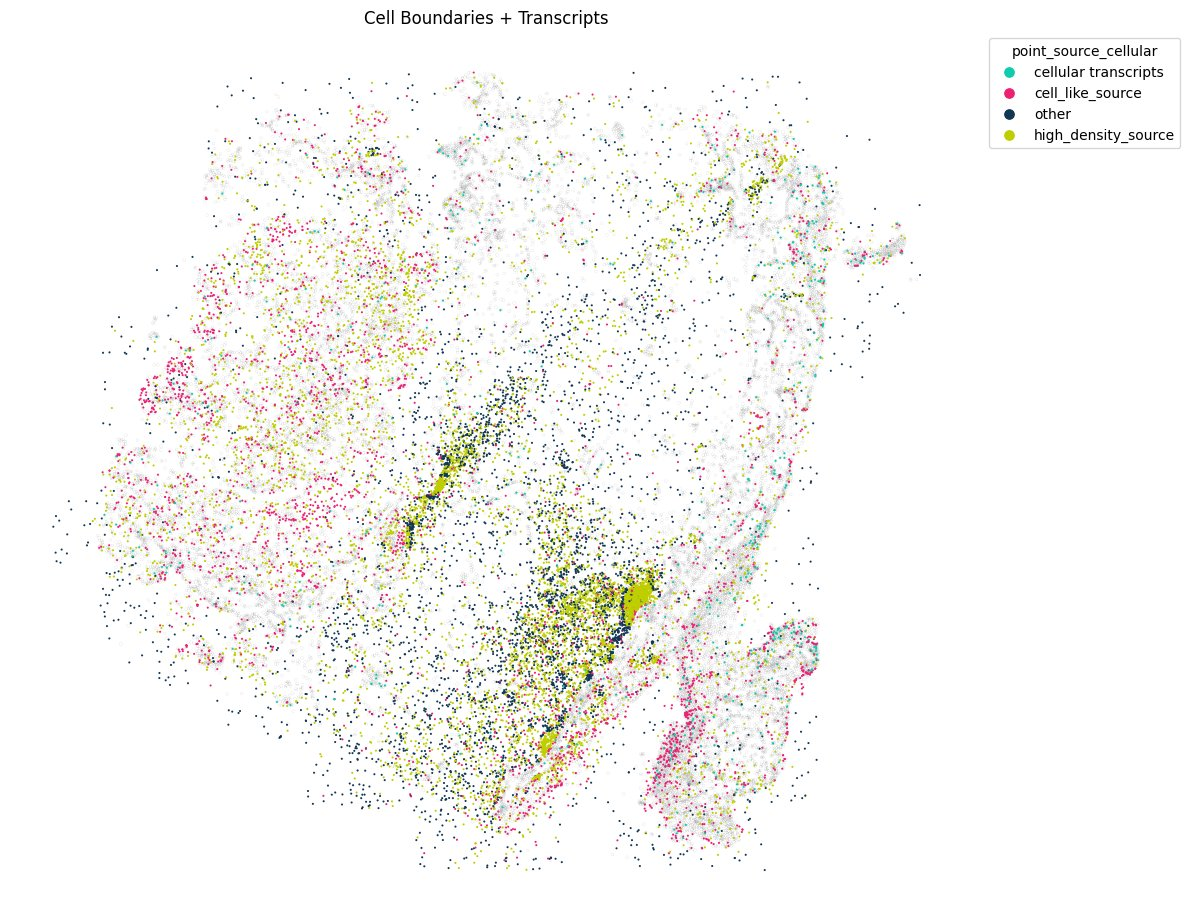

In [ ]:
fig=pl.spatial_transcripts(sdata,scatter_size=0.1,boundary_linewidth=0.06,alpha=1,figsize=(12,12))
plt.savefig(os.path.join(saving_path,'msbrain_by_transcript_type.pdf'))
fig=pl.spatial_transcripts(sdata,scatter_size=1.2,gene_list=['AQP3'],boundary_linewidth=0.1,alpha=1,figsize=(12,12))
plt.savefig(os.path.join(saving_path,'hsfemur_by_transcript_type_AQP3.pdf'))
fig=pl.spatial_transcripts(sdata,scatter_size=1.5,gene_list=['OGN'],color_key='point_source_cellular',boundary_linewidth=0.1,alpha=1,figsize=(12,12))
plt.savefig(os.path.join(saving_path,'hsfemur_by_transcript_type_OGN.pdf'))

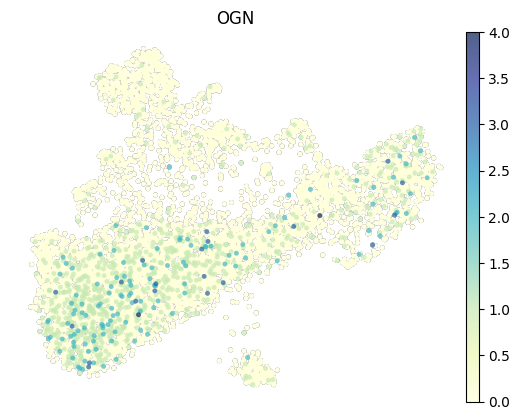

In [15]:
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.pl.umap(sdata['table'],color='OGN',s=50,frameon=False,add_outline=True,outline_width=(0.000,0.001),show=False,cmap='YlGnBu')
plt.savefig(os.path.join(saving_path,'umap_OGN.pdf'))

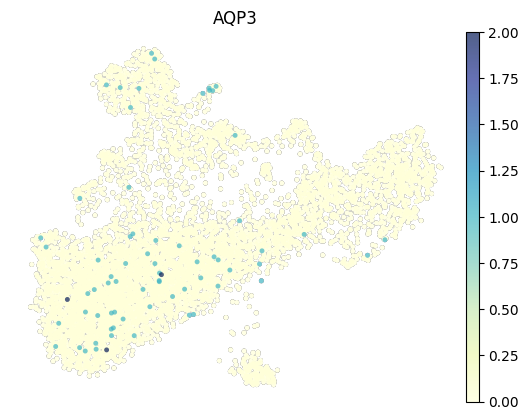

In [16]:
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.pl.umap(sdata['table'],color='AQP3',s=50,frameon=False,add_outline=True,outline_width=(0.000,0.001),show=False,cmap='YlGnBu')
plt.savefig(os.path.join(saving_path,'umap_AQP3.pdf'))

It seems you use rank_genes_groups on the raw count data. Please logarithmize your data before calling rank_genes_groups.


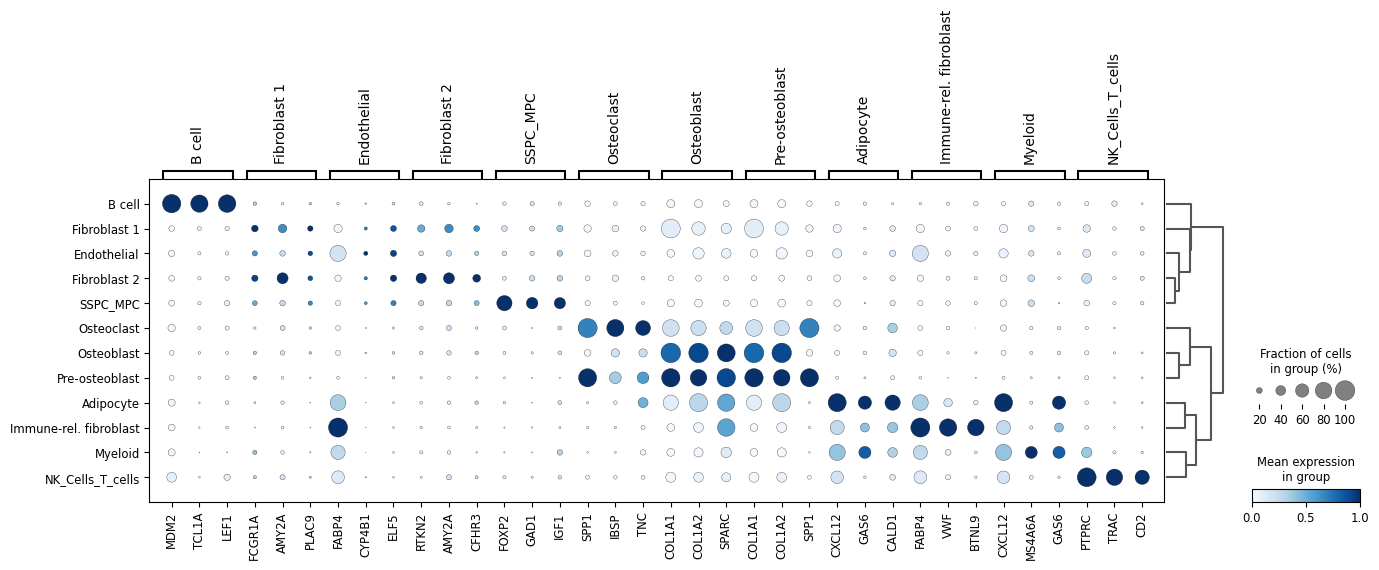

In [18]:
import matplotlib.pyplot as plt
import matplotlib

# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.tl.rank_genes_groups(sdata['table'],groupby='cell_type')
sc.tl.dendrogram(sdata['table'],groupby='cell_type')
sc.pl.rank_genes_groups_dotplot(sdata['table'],n_genes=3,show=False,cmap='Blues',standard_scale='var')
plt.savefig(os.path.join(saving_path,'dotplot_cell_type_map.pdf'))

In [19]:
# Read spatial data using the / operator for clean path joining
sdata.write(data_dir / "data_with_source_score_annotated.zarr")

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside                                                                                         
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_hsfemur/data_with_source_score_
         annotated.zarr). Please see the documentation of `is_self_contained()` to understand the implications of  
         working with SpatialData objects that are not self-contained.                                             
INFO     The Zarr backing store has been changed from                                                              
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_hsfemur/data_with_source_score.
         zarr the new file path:                                                                                   
         /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/

# 2. Multivariate analysis

In [175]:
troutpy.pp.aggregate_urna(sdata,gene_key='gene',square_size=70,radius=70)

In [177]:
adata = sdata.tables["segmentation_free_table"]
adata.raw = adata
sc.pp.filter_genes(adata, min_cells=2)
sc.pp.filter_cells(adata, min_genes=3)
sc.pp.filter_cells(adata, min_counts=8)

adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
# pca
sc.tl.pca(adata)
# neighbors
sc.pp.neighbors(adata, n_neighbors=10)
sc.tl.umap(adata)
sc.tl.leiden(adata, key_added="leiden", resolution=0.7)
sc.tl.rank_genes_groups(adata, "leiden", method="t-test", n_genes=3)

In [ ]:
sc.pl.umap(adata, color="leiden", palette="tab20", s=100)
# plot 
fig, ax = plt.subplots(figsize=(7, 7))
sc.pl.spatial(adata, color="leiden", spot_size=80, show=False, ax=ax)
# fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(sdata["table"],color="cell_type",spot_size=15,show=False, ax=ax,add_outline=True,outline_width=(0.1, 0.1))
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden", n_genes=3)

In [183]:
adata

AnnData object with n_obs × n_vars = 9420 × 525
    obs: 'instance_id', 'region', 'n_genes', 'n_counts', 'leiden'
    var: 'n_cells'
    uns: 'spatialdata_attrs', 'log1p', 'pca', 'neighbors', 'umap', 'leiden', 'rank_genes_groups', 'leiden_colors', 'dendrogram_leiden'
    obsm: 'spatial', 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'raw'
    obsp: 'distances', 'connectivities'

In [194]:
sdata['table'].obs['type']='cell'
adata.obs['type']='uRNA_bin'

In [195]:
adata.obs['cell_type']='bin'

In [196]:
condata=sc.concat([sdata['table'],adata])

In [197]:
sc.pp.neighbors(condata, n_neighbors=10)
sc.tl.umap(condata)

In [ ]:
sc.pl.umap(condata,color=['type','cell_type'])
sc.pl.umap(adata, color=["leiden",'OGN','n_counts'], s=120,vmax='p99.5')

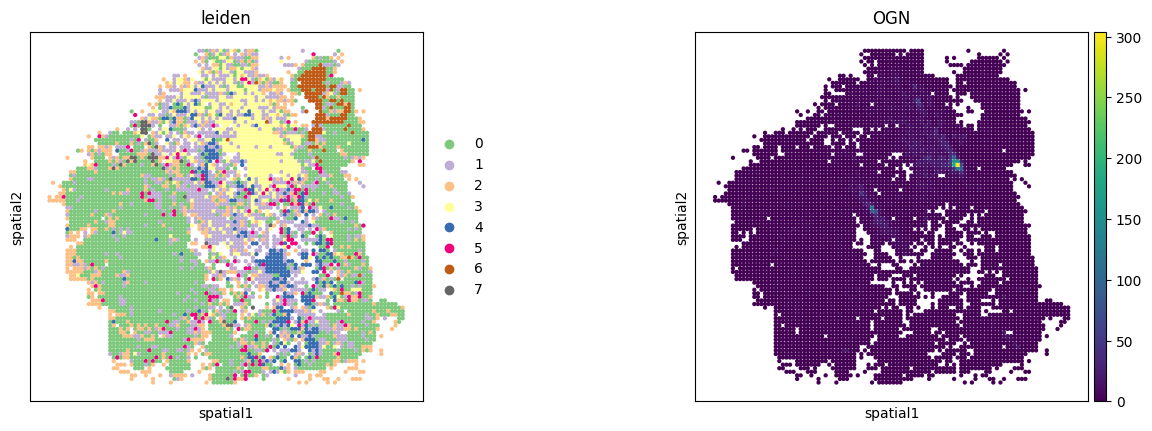

In [172]:
sc.pl.spatial(adata, color=["leiden",'OGN'], spot_size=120)

In [201]:
troutpy.tl.latent_factor(sdata, method="NMF", layer="segmentation_free_table", n_components=10)
troutpy.tl.factors_to_cells(sdata, extracellular_layer="segmentation_free_table", cellular_layer="table")


{'Factor 1': ['OGN', 'CD79A', 'AIF1'], 'Factor 2': ['LILRA4', 'LPL', 'GPC1'], 'Factor 3': ['KCNN3', 'AIF1', 'DKK1'], 'Factor 4': ['CAVIN2', 'CD69', 'PDCD1'], 'Factor 5': ['SOST', 'MEPE', 'DMP1'], 'Factor 6': ['CLDN10', 'SMIM24', 'SDC1'], 'Factor 7': ['SLC4A1', 'CYP2F1', 'LRP6'], 'Factor 8': ['NMU', 'CD247', 'GALNT5'], 'Factor 9': ['MEIS2', 'TMEM52B', 'CD3E'], 'Factor 10': ['AQP3', 'NegControlCodeword_0515', 'CD28']}


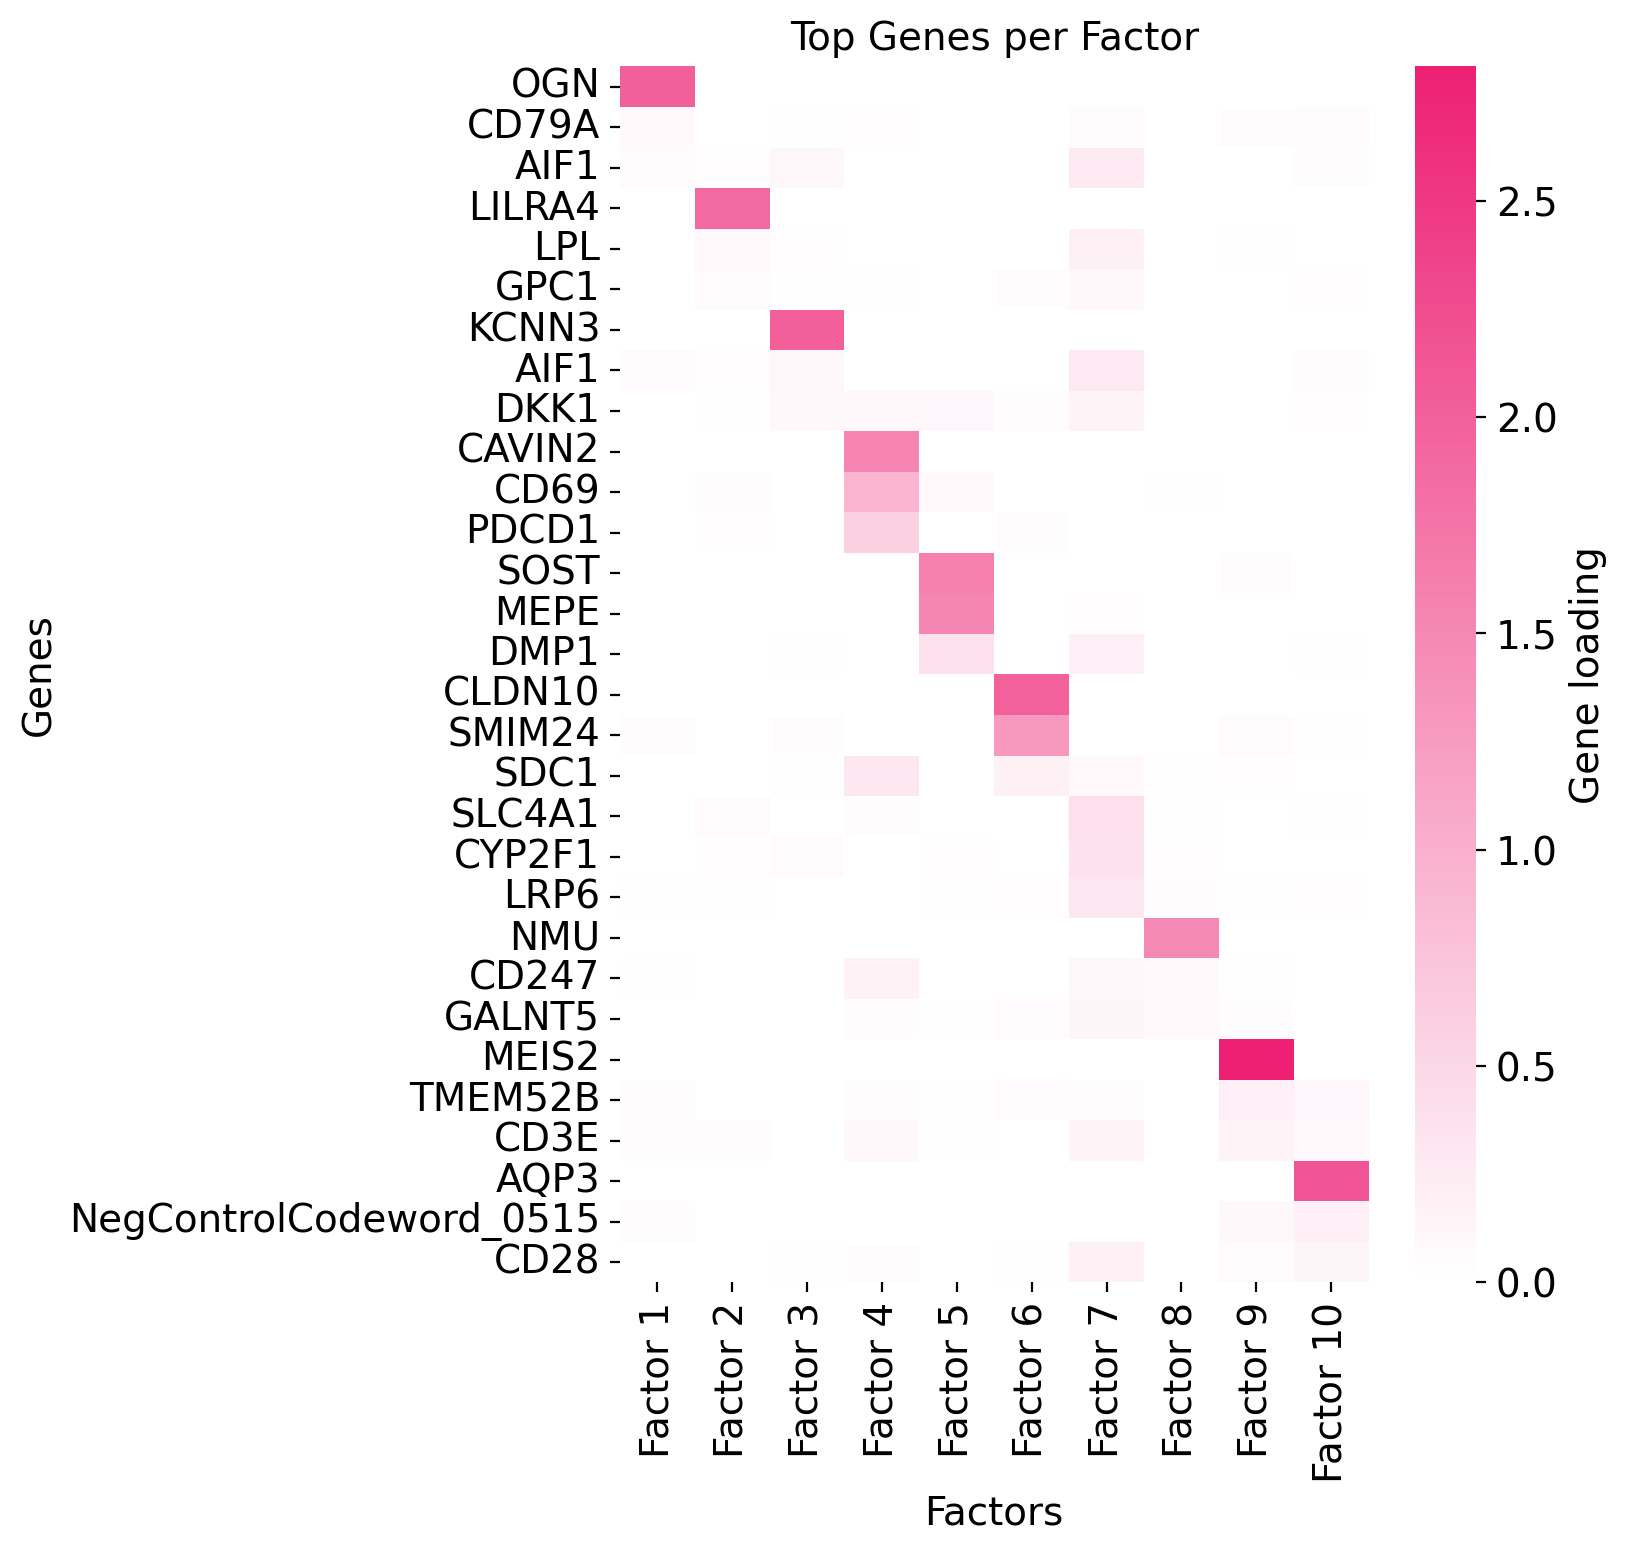

In [225]:
sc.set_figure_params(scanpy=True, dpi=100, dpi_save=100, frameon=True, vector_friendly=True, fontsize=14, figsize=None, color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')
troutpy.pl.rank_factor_genes_loadings_matrixplot(sdata, layer="segmentation_free_table", n_genes=3,figsize=(6,8),save=saving_path)

In [ ]:
sc.pl.umap(sdata['table'],color='cell_type')

In [218]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import troutpy as tp

def plot_factor_loadings(sdata, layer_cells="table", layer_extra="segmentation_free_table", spot_size_cells=7, spot_size_extra=12,complete_saving_path=None):
    """
    Plots factor loadings for each factor in a single figure with subplots,showing both intra- and extra-cellular scores.

    Parameters
    ----------
    sdata
        SpatialData object containing cell and extra-cellular data.

    layer_cells
        Key in sdata where *cell* factor loadings are stored.

    layer_extra
        Key in sdata where *extra-cellular* factor loadings are stored.

    spot_size_cells
        Size of the marker for cells.

    spot_size_extra
        Size of the marker for extra-cellular spots.
    """
    cell_loadings = sc.AnnData(sdata[layer_cells].obsm["factors_cell_loadings"], obs=sdata[layer_cells].obs)
    cell_loadings.var.index = [f"Factor {i + 1}" for i in range(cell_loadings.shape[1])]
    cell_loadings.obsm["spatial"] = sdata[layer_cells].obsm["spatial"]

    extra_loadings = sc.AnnData(sdata[layer_extra].obsm["cell_loadings"], obs=sdata[layer_extra].obs)
    extra_loadings.var.index = [f"Factor {i + 1}" for i in range(extra_loadings.shape[1])]
    extra_loadings.obsm["spatial"] = sdata[layer_extra].obsm["spatial"]

    n_factors = cell_loadings.shape[1]

    cold_palette = tp.pl.get_colormap("Aquas_contrast")  # For intra-cellular factors
    warm_palette = tp.pl.get_colormap("Pinks")  # For extra-cellular factors

    n_cols = 2  # Number of columns in the grid
    n_rows = int(np.ceil(n_factors / n_cols))  # Compute number of rows needed
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 10 * n_rows))
    axes = axes.flatten()  # Flatten in case of single row

    for i in range(n_factors):
        ax = axes[i]
        factor_name = f"Factor {i + 1}"

        # Plot extra-cellular loadings (background)
        sc.pl.spatial(
            extra_loadings, color=factor_name, spot_size=spot_size_extra, show=False, ax=ax, cmap=warm_palette, colorbar_loc=None,vmax='p99'
        )

        # Plot intra-cellular loadings (foreground with black outline)
        sc.pl.spatial(
            cell_loadings,
            color=factor_name,
            spot_size=spot_size_cells,
            show=False,
            ax=ax,
            cmap=cold_palette,
            edgecolor="black",
            linewidth=0.03,
            colorbar_loc=None, vmax='p99'
        )

        ax.set_title(factor_name)

    # Remove empty subplots if n_factors is not a multiple of n_cols
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    if complete_saving_path is not None:
        plt.savefig(complete_saving_path)
    plt.show()

In [ ]:
plot_factor_loadings(sdata, layer_cells="table", layer_extra="segmentation_free_table", spot_size_cells=60,spot_size_extra=80,complete_saving_path=os.path.join(saving_path,'factors_urna_cells_bone.pdf'))

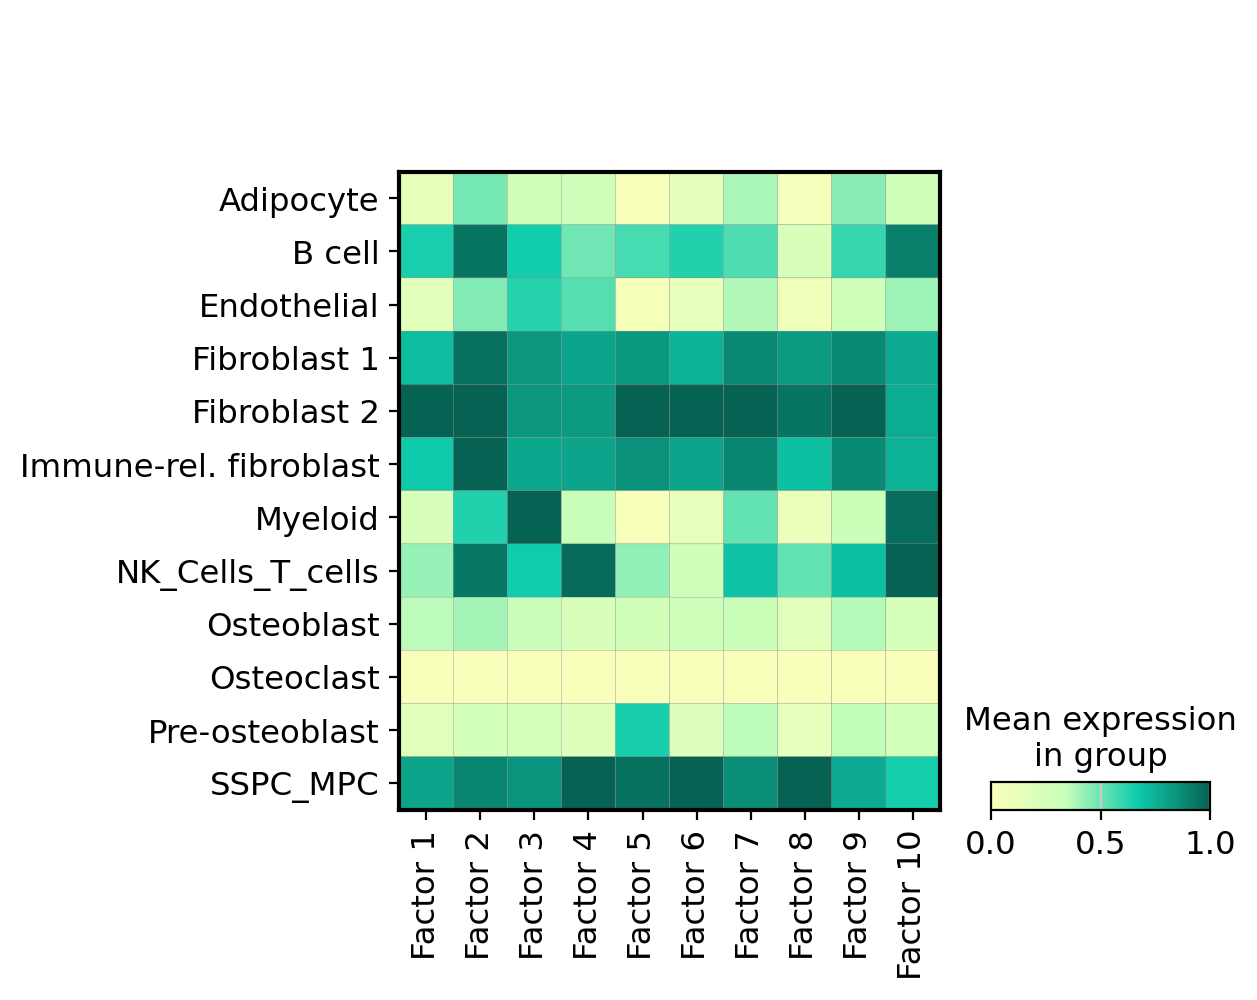

In [230]:
troutpy.pl.factors_in_cells(sdata, layer="table", cmap='Aquas_contrast', method="matrixplot",celltype_key='cell_type',standard_scale='var',show=False)
plt.savefig(os.path.join(saving_path, 'factors_scores_per_celltype_femur_norm.pdf'))

In [ ]:
sc.pl.umap(sdata["table"],color="leiden")
sc.pl.spatial(sdata["table"],color="leiden",spot_size=6,add_outline=False,outline_width=(0.5, 0))
sc.pl.rank_genes_groups_dotplot(sdata['table'],groupby='leiden',n_genes=10)

In [ ]:
troutpy.pl.spatial_transcripts(sdata,shapes_key='shapes',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.3)
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT1'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT1')
troutpy.pl.spatial_transcripts(sdata,gene_list=['FABP5'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='FABP5')

In [ ]:
troutpy.pl.spatial_transcripts(sdata,shapes_key='shapes',color_key='closest_cell_type',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.3)

In [ ]:
troutpy.pl.source_score_by_celltype(sdata, figsize=(4, 6))

In [ ]:
troutpy.tl.cluster_distribution_from_source(sdata, n_clusters=4)

In [ ]:
troutpy.pl.global_distribution_from_source(sdata, cluster_key="kmeans_distribution", distance_key="distance", n_bins=40, how="collapsed")


In [ ]:
troutpy.pl.distributions_by_cluster(sdata, groups=[1])

In [ ]:
troutpy.tl.cluster_distribution_from_source(sdata, n_clusters=4)

In [ ]:
troutpy.pl.global_distribution_from_source(sdata,cluster_key="kmeans_distribution")

In [ ]:
cool_pattern_df = sdata["xrna_metadata"].var[sdata["xrna_metadata"].var["kmeans_distribution"] == 1.0]
selected_genes = cool_pattern_df.sort_values(by="count", ascending=False).index
troutpy.pl.gene_distribution_from_source(sdata, selected_genes[3:4])

## Target-score

In [ ]:
troutpy.tl.compute_target_score(sdata,layer="transcripts",lambda_decay=0.5,copy=False,celltype_key="leiden",gene_key='gene')

In [ ]:
troutpy.pl.target_score_by_celltype(sdata, figsize=(5, 5),gene_key='gene')

## Communication strenght

In [ ]:
troutpy.tl.gene_specific_interactions(sdata, copy=False)

## Latent factor analysis

In [ ]:
troutpy.tl.latent_factor(sdata, method="NMF", layer="segmentation_free_table", n_components=10)

In [ ]:
troutpy.pl.rank_factor_genes_loadings_matrixplot(sdata, layer="segmentation_free_table", n_genes=1, cmap="troutpy_reversed")

In [ ]:
troutpy.pl.rank_factor_genes_loadings(sdata, layer="segmentation_free_table", n_genes=10)

In [ ]:
troutpy.pl.factors_in_cells(sdata, layer="table", cmap="troutpy", method="heatmap",celltype_key='leiden')

In [211]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc

import troutpy as tp


def plot_factor_loadings(sdata, layer_cells="table", layer_extra="segmentation_free_table", spot_size_cells=7, spot_size_extra=12):
    """
    Plots factor loadings for each factor in a single figure with subplots,showing both intra- and extra-cellular scores.

    Parameters
    ----------
    sdata
        SpatialData object containing cell and extra-cellular data.

    layer_cells
        Key in sdata where *cell* factor loadings are stored.

    layer_extra
        Key in sdata where *extra-cellular* factor loadings are stored.

    spot_size_cells
        Size of the marker for cells.

    spot_size_extra
        Size of the marker for extra-cellular spots.
    """
    cell_loadings = sc.AnnData(sdata[layer_cells].obsm["factors_cell_loadings"], obs=sdata[layer_cells].obs)
    cell_loadings.var.index = [f"Factor {i + 1}" for i in range(cell_loadings.shape[1])]
    cell_loadings.obsm["spatial"] = sdata[layer_cells].obsm["spatial"]

    extra_loadings = sc.AnnData(sdata[layer_extra].obsm["cell_loadings"], obs=sdata[layer_extra].obs)
    extra_loadings.var.index = [f"Factor {i + 1}" for i in range(extra_loadings.shape[1])]
    extra_loadings.obsm["spatial"] = sdata[layer_extra].obsm["spatial"]

    n_factors = cell_loadings.shape[1]

    cold_palette = tp.pl.get_colormap("Aquas")  # For intra-cellular factors
    warm_palette = tp.pl.get_colormap("Pinks")  # For extra-cellular factors

    n_cols = 2  # Number of columns in the grid
    n_rows = int(np.ceil(n_factors / n_cols))  # Compute number of rows needed
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 10 * n_rows))
    axes = axes.flatten()  # Flatten in case of single row

    for i in range(n_factors):
        ax = axes[i]
        factor_name = f"Factor {i + 1}"

        # Plot extra-cellular loadings (background)
        sc.pl.spatial(
            extra_loadings, color=factor_name, spot_size=spot_size_extra, show=False, ax=ax, cmap=warm_palette, colorbar_loc=None
        )

        # Plot intra-cellular loadings (foreground with black outline)
        sc.pl.spatial(
            cell_loadings,
            color=factor_name,
            spot_size=spot_size_cells,
            show=False,
            ax=ax,
            cmap=cold_palette,
            edgecolor="black",
            linewidth=0.5,
            colorbar_loc=None,
        )

        ax.set_title(factor_name)

    # Remove empty subplots if n_factors is not a multiple of n_cols
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

In [ ]:
plot_factor_loadings(sdata, layer_cells="table", layer_extra="segmentation_free_table", spot_size_cells=5)

In [ ]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT1'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT1')
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT14'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT14')

In [ ]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['FABP5'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='FABP5')

## Multimodal analysis

In [ ]:
sdata

### This is currently not working, to be fixed

In [ ]:
image_intensities_per_transcript(
sdata, image_key="morphology_focus", scale="scale0", transcript_key="transcripts", extracellular=True, copy=False,
)

In [ ]:
get_transformation(sdata['morphology_focus'])

In [ ]:
ad = sdata["image_intensity_per_transcript"]
sc.pl.spatial(ad, color=ad.var.index, spot_size=10, cmap="YlGnBu", vmax="p99", ncols=4)

# Module analysis

In [ ]:
adata = sdata["table"]
hs = hotspot.Hotspot(adata, layer_key="raw", model="danb", latent_obsm_key="X_pca", umi_counts_obs_key="n_counts")

hs.create_knn_graph(weighted_graph=False, n_neighbors=10)
hs_results = hs.compute_autocorrelations()
hs_genes = hs_results.loc[hs_results.FDR < 0.005].index  # Select genes
local_correlations = hs.compute_local_correlations(hs_genes, jobs=4)  # jobs for parallelization

In [ ]:
# calculate modules
modules = hs.create_modules(min_gene_threshold=10, core_only=True, fdr_threshold=0.0005)
module_scores = hs.calculate_module_scores()

In [ ]:
hs.plot_local_correlations(vmax=10, vmin=-10)

In [ ]:
adata_scores = sc.AnnData(module_scores, obs=adata.obs)
adata_scores.obsm["X_umap"] = adata.obsm["X_umap"]
adata_scores.obsm["X_pca"] = adata.obsm["X_pca"]
sc.pl.umap(adata, color="leiden")
sc.pl.umap(adata_scores, color=adata_scores.var.index, vmax="p99")

In [ ]:
dictmod = dict(zip(modules.index, modules.values))
results=sdata['xrna_metadata'].var
results["module"] = results.index.map(dictmod)

In [ ]:
import matplotlib.pyplot as plt


def annotate_top_bottom(
    df, metric1, metric2, n=5, label_col=None, figsize=(8, 6), scatter_kwargs=None, annotate_kwargs=None, title_tag=""
):
    """
    Scatter-plot df[metric1] vs df[metric2] and annotate the top/bottom n points
    along each axis.

    Parameters
    ----------
    df : pandas.DataFrame
        The data.
    metric1 : str
        Column name for the x-axis metric.
    metric2 : str
        Column name for the y-axis metric.
    n : int, optional (default=5)
        Number of top and bottom points to label per metric.
    label_col : str or None, optional (default=None)
        Column name containing the labels. If None, uses df.index.
    figsize : tuple, optional (default=(8, 6))
        Figure size.
    scatter_kwargs : dict or None
        Extra kwargs passed to plt.scatter().
    annotate_kwargs : dict or None
        Extra kwargs passed to plt.annotate().
    Title tag: str, optional (default='')

    Returns
    -------
    fig, ax : matplotlib.figure.Figure, matplotlib.axes.Axes
        The figure and axes objects.
    """
    # Prepare labels
    df_plot = df.copy()
    if label_col is None:
        df_plot["__idx_label"] = df_plot.index.astype(str)
        label_col = "__idx_label"

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    sc_kwargs = {} if scatter_kwargs is None else scatter_kwargs
    ax.scatter(df_plot[metric1], df_plot[metric2], **sc_kwargs)
    ax.set_xlabel(metric1)
    ax.set_ylabel(metric2)
    ax.set_title(f"{title_tag}: {metric1} vs {metric2}")

    # Find indices to annotate
    top1 = df_plot.nlargest(n, metric1).index
    bot1 = df_plot.nsmallest(n, metric1).index
    top2 = df_plot.nlargest(n, metric2).index
    bot2 = df_plot.nsmallest(n, metric2).index
    to_annotate = set(top1) | set(bot1) | set(top2) | set(bot2)

    # Annotate
    ann_kwargs = dict(xytext=(5, 5), textcoords="offset points", ha="left", va="bottom", fontsize=8, alpha=0.8)
    if annotate_kwargs:
        ann_kwargs.update(annotate_kwargs)

    for idx in to_annotate:
        x = df_plot.loc[idx, metric1]
        y = df_plot.loc[idx, metric2]
        label = df_plot.loc[idx, label_col]
        ax.annotate(label, xy=(x, y), **ann_kwargs)

    fig.tight_layout()
    return fig, ax

In [ ]:
results2 = results[results["logfoldratio_over_noise"] > 0]
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="in_out_spearmanR",
    n=10,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

In [ ]:
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=50,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

In [ ]:
# spatial maps-in out
g2 = "Gap43"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10)

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="extracellular_proportion",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="in_out_spearmanR",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

In [ ]:
import pandas as pd

mods_df = pd.DataFrame(modules).sort_values(by="Module")
genes = mods_df[mods_df["Module"] == 1].index
sc.pl.umap(adata, color=genes, vmax="p99")
print(genes)

In [ ]:
g2 = "CAVIN2"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=40, spot_size_extra=40)

In [ ]:
g2 = "FABP4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=40, spot_size_extra=40)

In [ ]:
merged_info.sort_values(by=[metric + "_cosmx"], ascending=False)

In [ ]:
fig, ax = annotate_top_bottom(
    df=results,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=5,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    title_tag=g,
    figsize=(4, 4),
)
plt.show()

In [ ]:
g2 = "FZD4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10, spot_size_extra=10)

In [ ]:
trans = sdata["transcripts"].compute()

In [ ]:
trans["segstatus"] = trans["overlaps_cell"].astype(str) + "_" + trans["extracellular"].astype(str)
stat2lab = {"True_False": "cell", "False_True": "extracellular", "False_False": "cell-like"}

In [ ]:
trans["type"] = trans["segstatus"].map(stat2lab)

In [ ]:
trans2 = trans.loc[:, ["x", "y", "gene", "type"]]

In [ ]:
trans2.to_csv("/media/sergio/Meninges/trans2.csv")